#  TP Impact of Social Media on life
### Dataset : *Impact of Social Media on Life* (4 500 étudiants, 16 colonnes)

Ce notebook est le notebook Kaggle d'origine, **non modifié** (cellules et sorties conservées) auquel j'ai ajouté :

1. **Sous les cellules d'origine**, des blocs de commentaires `🔎 Analyse critique` qui disent si chaque étape de la pipeline
   **Data → EDA → Prétraitement → Transformation → ML (validation croisée) → Évaluation** est bien réalisée, incomplète ou erronée.
2. **À la fin (Partie 2)**, les étapes manquantes ou corrigées, exécutées.

Légende : ✅ correct  ·  ⚠️ incomplet / discutable  ·  ❌ erreur ou étape absente

---

## Synthèse de l'audit

| Étape | État | Ce qui ne va pas |
|---|---|---|
| **Data** | ✅ / ⚠️ | Chargement correct, mais **aucune définition du problème** (quelle cible ? classification binaire ou à 3 classes ? pourquoi ?). Chemin Kaggle codé en dur. |
| **EDA** | ⚠️ | 13 graphiques sur les variables explicatives, mais **la variable cible n'est jamais étudiée** (déséquilibre 82 % / 15 % / 4 % non vu), **aucune interprétation écrite**, valeurs aberrantes non étudiées, et la heatmap de corrélation **perd 2 variables** à cause du bug d'imputation. |
| **Prétraitement** | ❌ | **Bug 1** : `fillna(df[col].mean)` sans parenthèses → les NaN sont remplacés par *l'objet méthode* et non par la moyenne : l'imputation ne fait rien. **Bug 2** : la cible est encodée avec `'Harmful'` alors que la modalité réelle est `'Negative'` → les 165 étudiants « Negative » deviennent NaN. Les deux bugs sont masqués par `to_numeric(errors='coerce')` + `dropna()` : **293 lignes (6,5 %) supprimées en silence, dont toute la classe la plus intéressante.** |
| **Transformation** | ⚠️ | Standardisation bien faite (fit sur le train uniquement 👍), mais : encodage fait avant le split, variable ordinale (`Social_Comparison_Frequency`) encodée en one-hot, pas de `Pipeline` → impossible de faire une validation croisée propre. |
| **ML** | ❌ | **Pas de validation croisée** (un seul split + `validation_split`), **pas de modèle de référence (baseline)**, aucun autre modèle comparé, pas de graine aléatoire (résultats non reproductibles), pas d'early stopping, aucun réglage d'hyperparamètres. |
| **Évaluation** | ⚠️ | **Accuracy seule** sur des données déséquilibrées : un modèle qui répond toujours « Beneficial » obtient déjà **84,9 %** sur les données de l'auteur. Pas de précision/rappel/F1/ROC-AUC, courbes d'apprentissage non tracées, aucune interprétation du modèle. |

**Conclusion de l'audit :** le score de 98,3 % est obtenu sur un jeu de données amputé de sa classe minoritaire, sans validation croisée ni point de comparaison. La Partie 2 montre qu'une simple **régression logistique** fait aussi bien ou mieux que le réseau de neurones, une fois la pipeline corrigée.


# Importing

## Import Library

In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import tensorflow
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

ModuleNotFoundError: No module named 'tensorflow'

> ### 🔎 Analyse critique — Imports
>
> ⚠️ **Reproductibilité** : aucune graine aléatoire n'est fixée (`np.random.seed`, `tf.random.set_seed`, `random.seed`). L'initialisation des poids, le dropout et l'ordre des mini-batchs changent à chaque exécution → le score de 98,3 % n'est pas reproductible à l'identique.
>
> ⚠️ Code « template » Kaggle laissé tel quel (`os.walk`, `kagglehub` importé mais jamais utilisé). Ce n'est pas une erreur, mais ça alourdit le notebook.

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('/kaggle/input/datasets/harishyadav0506/impact-of-social-media-on-life/Social_media_impact_on_life.csv')

> ### 🔎 Analyse critique — Étape « Data »
>
> ✅ Le chargement fonctionne.
>
> ❌ **Il manque la définition du problème** avant toute analyse : quelle est la variable cible (`Overall_Impact`) ? Quelles sont ses modalités ? S'agit-il d'une classification binaire ou à 3 classes, et pourquoi ? Que représente chaque variable (unités, échelles : le stress est-il sur 0–40 ? l'indice de santé mentale sur 0–100 ?) ?
> Sans cette étape, l'auteur n'a pas vu que la cible contient `Negative` (et non `Harmful`), ce qui provoque le bug de la cellule *Prepare features*.
>
> ⚠️ Chemin codé en dur sur Kaggle : le notebook ne tourne pas ailleurs sans modification.

# Preprocessing

> ### 🔎 Analyse critique — Organisation
>
> ⚠️ Cette section s'appelle *Preprocessing*, mais `head`, `tail`, `shape`, `columns`, `dtypes`, `info`, `describe` relèvent de la **découverte des données / EDA**, pas du prétraitement. Le seul vrai prétraitement de cette section est la cellule `fillna` (qui est buggée, voir plus bas). Mélanger les étapes rend la pipeline difficile à suivre.

## First five row

In [ ]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


## last Five row

In [4]:
df.tail()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
4495,STU_2028495,16,Male,High School,YouTube,5.8,1.2,Smartphone,7.8,3,True,Sometimes,11.0,79,2.85,Beneficial
4496,STU_2028496,19,Female,Undergraduate,LinkedIn,3.8,3.0,Smartphone,6.6,3,False,Frequently,9.0,83,3.37,Beneficial
4497,STU_2028497,19,Male,Undergraduate,Instagram,7.7,1.1,Smartphone,6.0,2,True,Frequently,13.0,73,3.16,Beneficial
4498,STU_2028498,16,Male,High School,LinkedIn,4.6,3.3,Laptop/PC,7.1,3,False,Sometimes,22.0,87,3.50,Beneficial
4499,STU_2028499,24,Male,Undergraduate,Instagram,1.8,2.1,Smartphone,6.8,3,True,Frequently,10.0,98,3.73,Beneficial


## Shape of our dataset

In [5]:
df.shape

(4500, 16)

## List out all columns

In [6]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Primary_Platform',
       'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Device_Type',
       'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Usage',
       'Social_Comparison_Frequency', 'Perceived_Stress_Score',
       'Mental_Health_Index', 'Academic_Performance_GPA', 'Overall_Impact'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

Student_ID                      object
Age                              int64
Gender                          object
Academic_Level                  object
Primary_Platform                object
Daily_Usage_Hours              float64
Weekend_Extra_Hours            float64
Device_Type                     object
Sleep_Duration_Hours           float64
Sleep_Quality_Score              int64
Late_Night_Usage                  bool
Social_Comparison_Frequency     object
Perceived_Stress_Score         float64
Mental_Health_Index              int64
Academic_Performance_GPA       float64
Overall_Impact                  object
dtype: object

> ### 🔎 Analyse critique — Types des colonnes
>
> ⚠️ Les types sont affichés mais **pas commentés**. Il fallait noter ici :
> - `Student_ID` est un identifiant → à supprimer (fait plus tard, ✅) ;
> - `Late_Night_Usage` est booléen → à convertir en 0/1 ;
> - 5 variables catégorielles à encoder, dont `Social_Comparison_Frequency` qui est **ordinale** (Never < Rarely < Sometimes < Frequently < Always) ;
> - `Sleep_Quality_Score` est un score entier de 1 à 5 (ordinal lui aussi).

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   object 
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   object 
 3   Academic_Level               4500 non-null   object 
 4   Primary_Platform             4500 non-null   object 
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   object 
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   object 
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Inde

## Check Null Value

In [9]:
df.isnull().sum()

Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64

> ### 🔎 Analyse critique — Valeurs manquantes
>
> ✅ Bonne vérification : 46 valeurs manquantes pour `Perceived_Stress_Score` (1,0 %) et 85 pour `Academic_Performance_GPA` (1,9 %).
>
> ⚠️ Il manque une analyse du **mécanisme** des valeurs manquantes : sont-elles réparties au hasard, ou concentrées dans une classe de la cible ? (voir Partie 2, section 2.7). C'est ce qui permet de choisir entre suppression et imputation.

In [10]:
df['Perceived_Stress_Score'] = df['Perceived_Stress_Score'].fillna(df['Perceived_Stress_Score'].mean)
df['Academic_Performance_GPA'] = df['Academic_Performance_GPA'].fillna(df['Academic_Performance_GPA'].mean)

> ### 🔎 Analyse critique — ❌ BUG MAJEUR — imputation
>
> ```python
> df['Perceived_Stress_Score'].fillna(df['Perceived_Stress_Score'].mean)   # ← il manque ()
> ```
> `.mean` sans parenthèses désigne **la méthode elle-même**, pas sa valeur. Les NaN sont donc remplacés par un objet `<bound method Series.mean ...>`, et les deux colonnes passent du type `float64` au type `object`.
>
> **Conséquences en cascade** (vérifiées en rejouant le code) :
> 1. `df.describe()` (cellule *Summary*) n'affiche plus que 6 colonnes au lieu de 8 : le stress et le GPA ont disparu ;
> 2. la heatmap de corrélation (graphique 13) ignore ces deux variables, qui sont pourtant parmi les plus liées à la cible ;
> 3. plus loin, `pd.to_numeric(errors='coerce')` retransforme ces objets en NaN, puis `dropna()` **supprime les lignes** : l'imputation prévue n'a jamais eu lieu.
>
> **Autres remarques :**
> - même corrigée, l'imputation est faite **avant** le découpage train/test → la moyenne est calculée sur tout le jeu, y compris le test (fuite de données, faible ici mais mauvaise pratique). L'imputation doit être apprise sur le train seulement, idéalement dans un `Pipeline` ;
> - la **médiane** est préférable à la moyenne pour le stress (distribution asymétrique).
>
> ✔️ Correction : `fillna(df[col].median())`, ou mieux `SimpleImputer(strategy='median')` dans un `Pipeline` (Partie 2, section 4).

## Check Duplicate Value

In [11]:
df.duplicated().sum()

np.int64(0)

> ### 🔎 Analyse critique — Doublons
>
> ✅ Pas de ligne dupliquée.
>
> ⚠️ Vérifications de cohérence absentes : unicité de `Student_ID`, modalités des variables catégorielles (fautes de frappe ? modalités rares ?), cohérence `Age` / `Academic_Level` (un lycéen de 26 ans ?). Voir Partie 2, sections 2.2 et 2.6.

## Summary

In [12]:
df.describe()

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Mental_Health_Index
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,79.873111
std,1.981182,2.604497,0.699245,1.189998,1.030484,12.876044
min,15.000000,0.900000,0.000000,3.000000,1.000000,32.000000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,72.000000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,82.000000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,89.000000
max,26.000000,14.000000,4.500000,10.500000,5.000000,98.000000


> ### 🔎 Analyse critique — Statistiques descriptives
>
> ❌ **Le tableau n'a que 6 colonnes numériques** : `Perceived_Stress_Score` et `Academic_Performance_GPA` manquent. C'est le symptôme visible du bug `fillna(... .mean)` de la cellule précédente, mais il n'a pas été remarqué.
>
> ⚠️ Aucune lecture du tableau : on pouvait déjà repérer les valeurs extrêmes (usage quotidien de 14 h, sommeil de 3 h, indice de santé mentale à 32), qui ne sont jamais discutées. Aucune analyse des valeurs aberrantes n'est faite ensuite.

# EDA

> ### 🔎 Analyse critique — Évaluation globale de l'EDA
>
> L'EDA de l'auteur contient 13 graphiques, ce qui est un bon début (distributions, boxplots, nuages de points, heatmap). Mais elle est **incomplète** :
>
> | Point attendu dans une EDA | Fait ? |
> |---|---|
> | Distribution de la **variable cible** (déséquilibre des classes) | ❌ jamais tracée |
> | Relation **cible ↔ variables explicatives** | ❌ aucun graphique n'utilise `Overall_Impact` |
> | Distributions univariées des variables numériques | ⚠️ 3 sur 8 |
> | Distributions des variables catégorielles | ❌ |
> | Valeurs aberrantes (outliers) | ❌ |
> | Corrélations / multicolinéarité | ⚠️ heatmap incomplète (bug) et non commentée |
> | **Interprétation écrite** de chaque graphique | ❌ aucune |
>
> Les compléments sont dans la **Partie 2, section 2**.

In [13]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

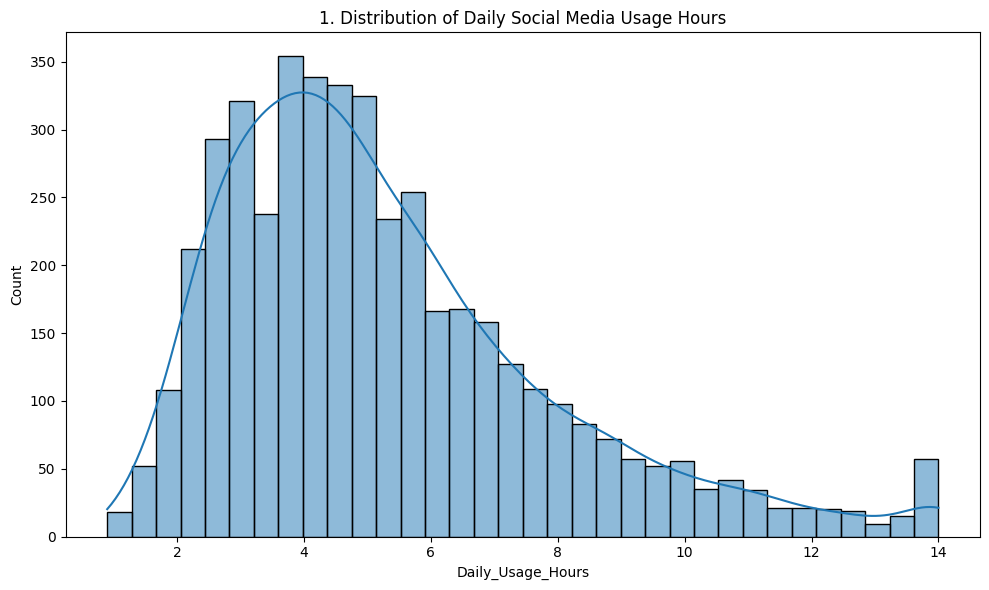

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Daily_Usage_Hours', kde=True)
plt.title(f'{plot_no}. Distribution of Daily Social Media Usage Hours')
show_fig()
plot_no += 1

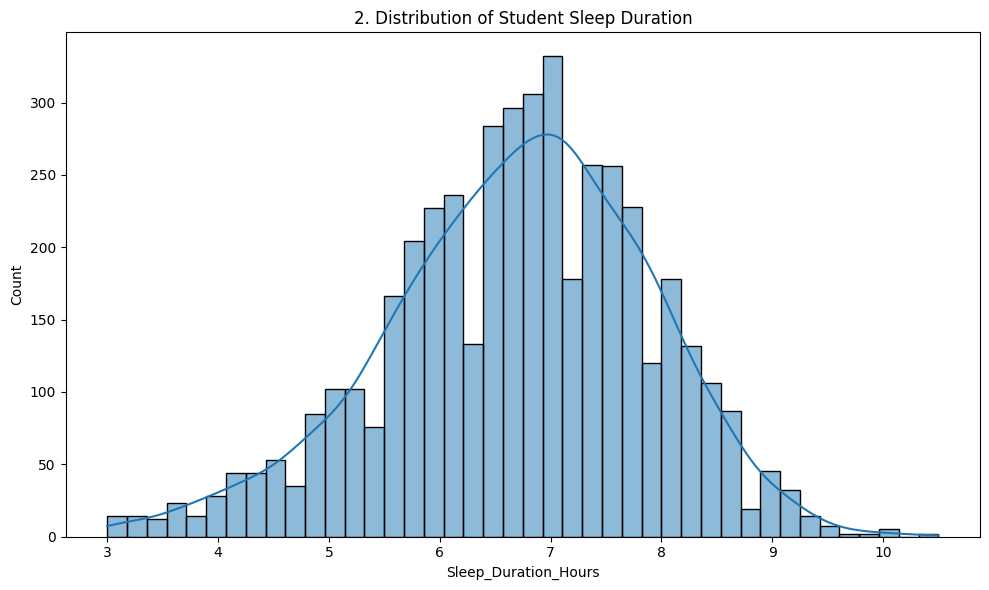

In [15]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Sleep_Duration_Hours', kde=True)
plt.title(f'{plot_no}. Distribution of Student Sleep Duration')
show_fig()
plot_no += 1

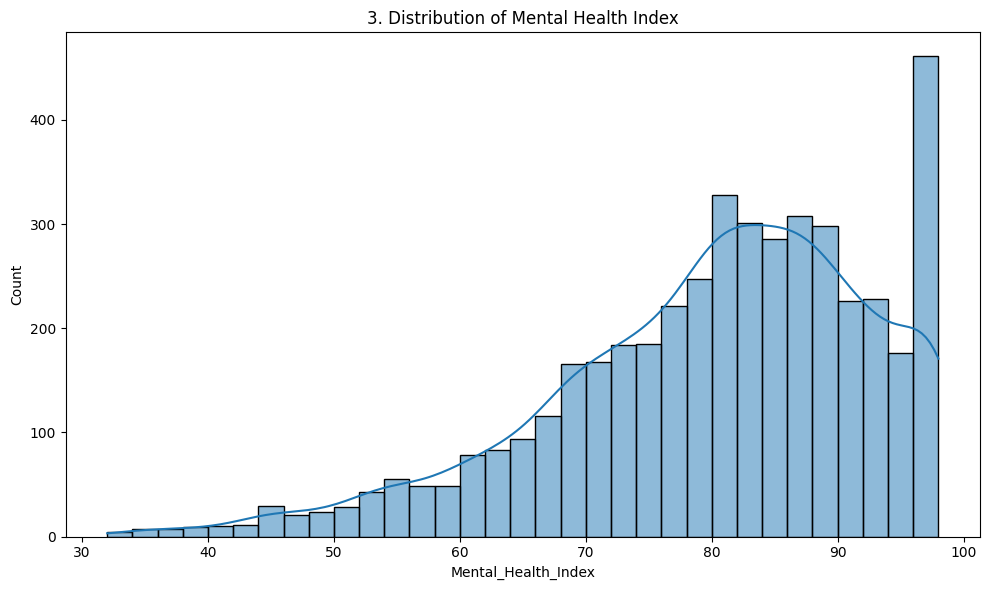

In [16]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Mental_Health_Index', kde=True)
plt.title(f'{plot_no}. Distribution of Mental Health Index')
show_fig()
plot_no += 1

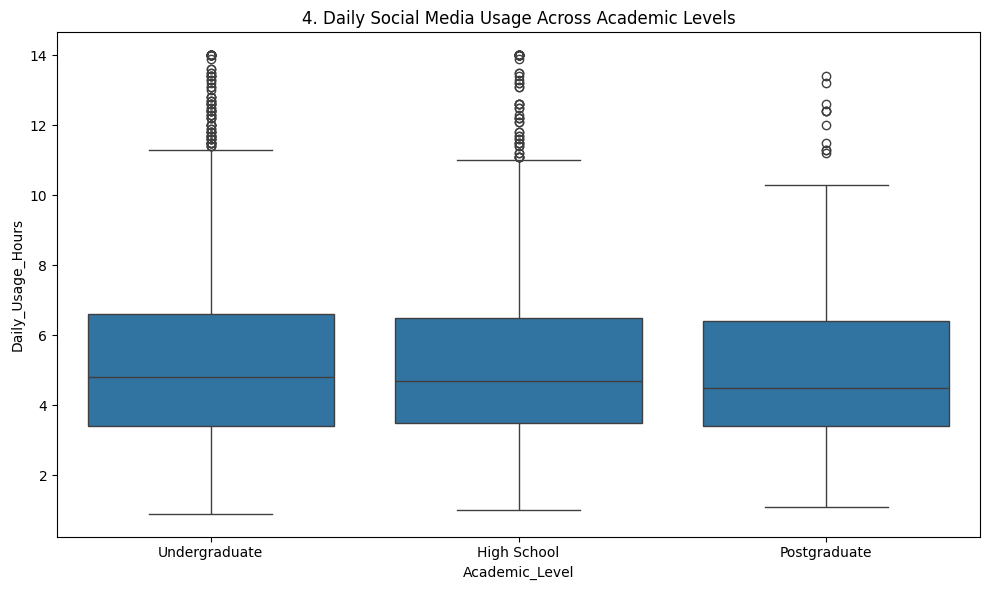

In [17]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Academic_Level', y='Daily_Usage_Hours')
plt.title(f'{plot_no}. Daily Social Media Usage Across Academic Levels')
show_fig()
plot_no += 1

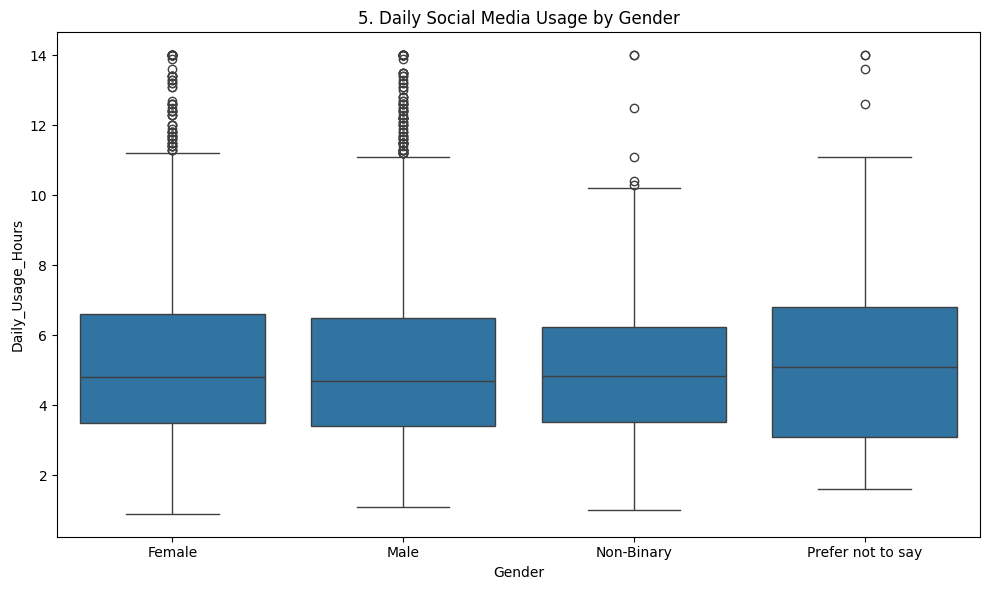

In [18]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Gender', y='Daily_Usage_Hours')
plt.title(f'{plot_no}. Daily Social Media Usage by Gender')
show_fig()
plot_no += 1

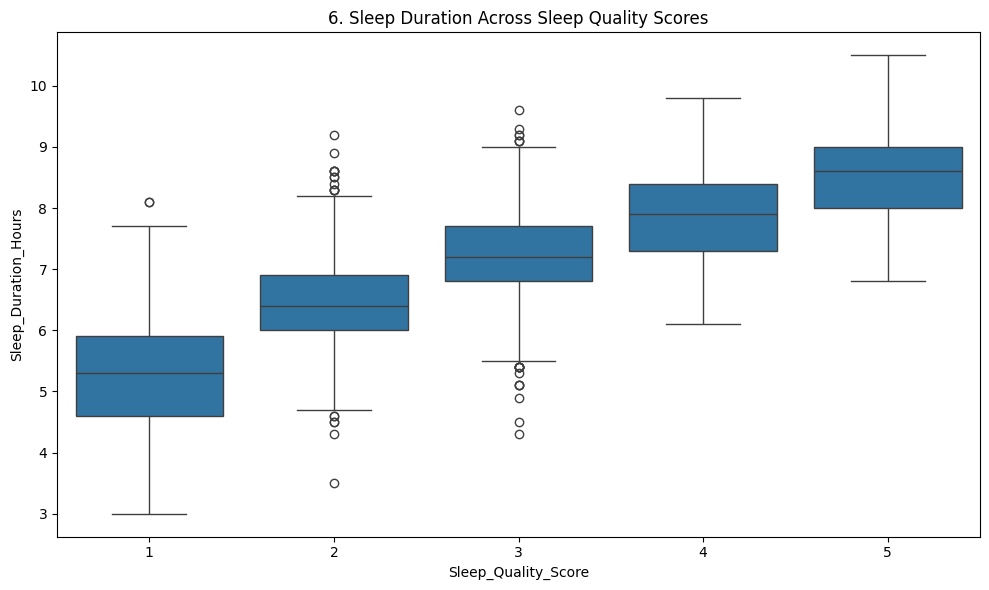

In [19]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Sleep_Quality_Score', y='Sleep_Duration_Hours')
plt.title(f'{plot_no}. Sleep Duration Across Sleep Quality Scores')
show_fig()
plot_no += 1

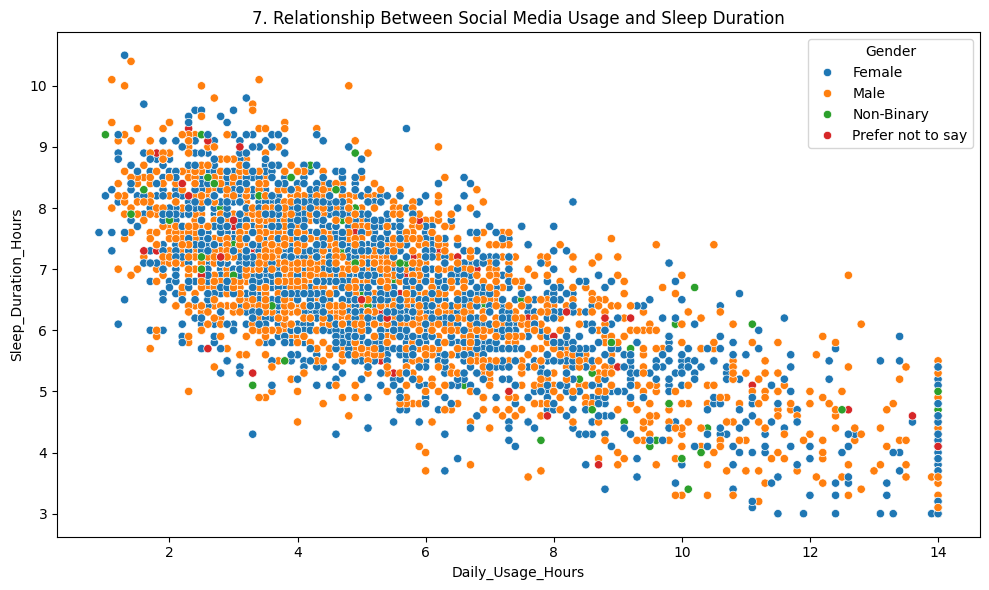

In [20]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Daily_Usage_Hours', y='Sleep_Duration_Hours', hue='Gender')
plt.title(f'{plot_no}. Relationship Between Social Media Usage and Sleep Duration')
show_fig()
plot_no += 1

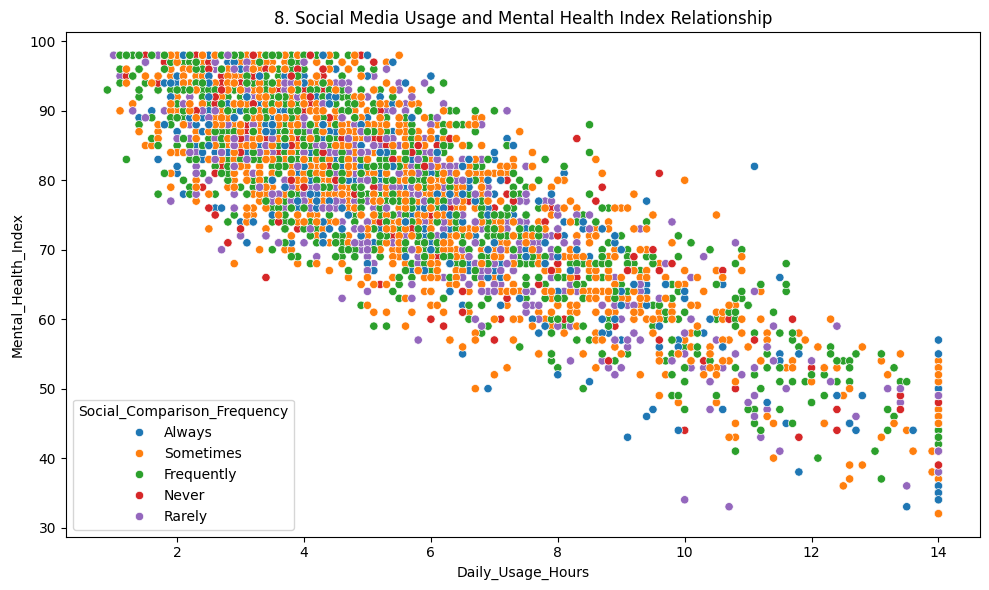

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Daily_Usage_Hours', y='Mental_Health_Index', hue='Social_Comparison_Frequency')
plt.title(f'{plot_no}. Social Media Usage and Mental Health Index Relationship')
show_fig()
plot_no += 1

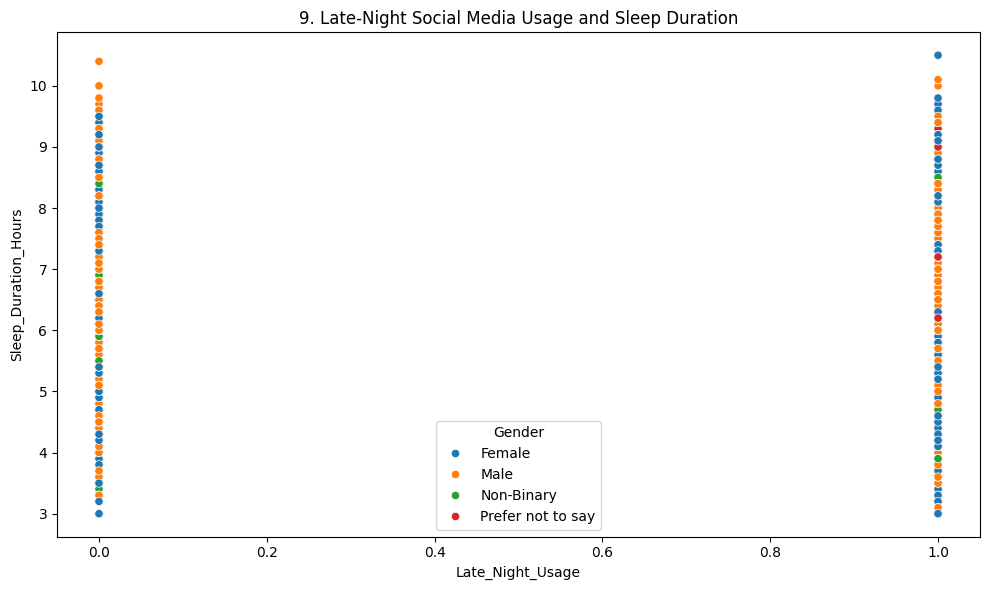

In [22]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Late_Night_Usage', y='Sleep_Duration_Hours', hue='Gender')
plt.title(f'{plot_no}. Late-Night Social Media Usage and Sleep Duration')
show_fig()
plot_no += 1

> ### 🔎 Analyse critique — Graphique 9
>
> ⚠️ **Type de graphique inadapté** : un nuage de points avec une variable booléenne (`Late_Night_Usage` = True/False) en abscisse empile tous les points sur deux colonnes verticales, illisibles. Un boxplot ou un violinplot (comme au graphique 11) est le bon choix pour croiser une variable binaire et une variable continue.

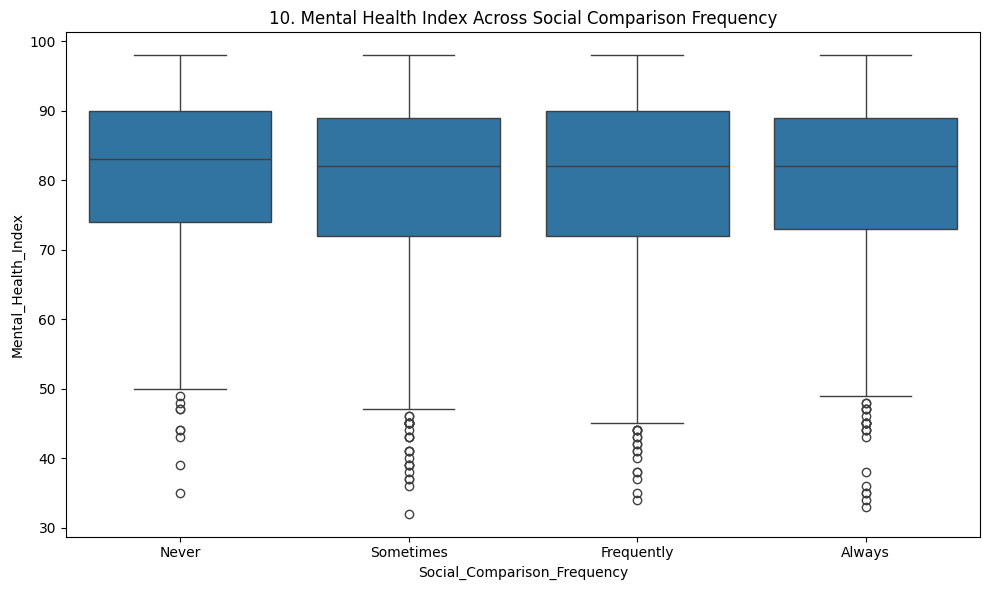

In [23]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Social_Comparison_Frequency', y='Mental_Health_Index', order=['Never', 'Sometimes', 'Frequently', 'Always'])
plt.title(f'{plot_no}. Mental Health Index Across Social Comparison Frequency')
show_fig()
plot_no += 1

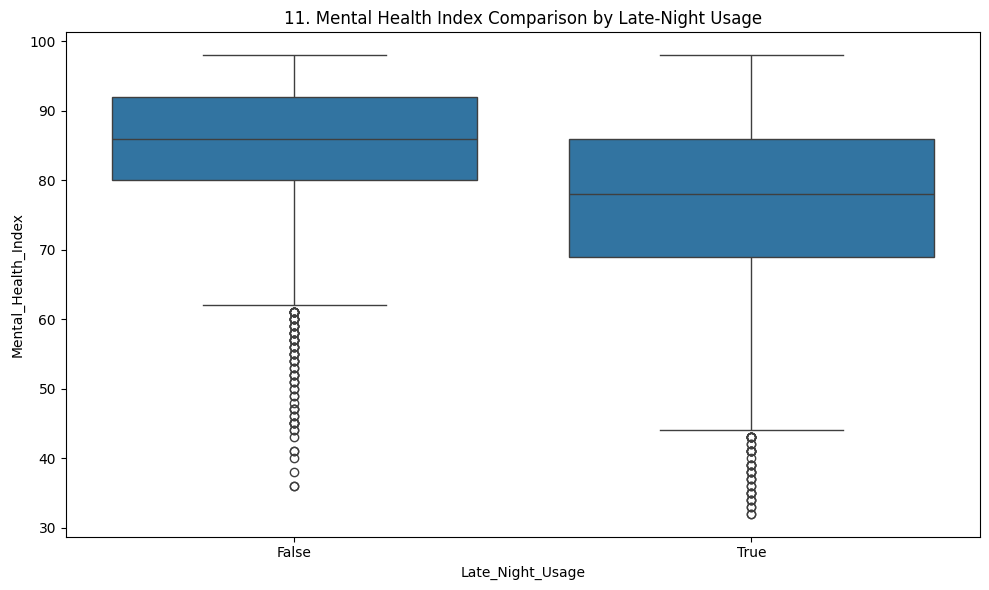

In [24]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Late_Night_Usage', y='Mental_Health_Index')
plt.title(f'{plot_no}. Mental Health Index Comparison by Late-Night Usage')
show_fig()
plot_no += 1

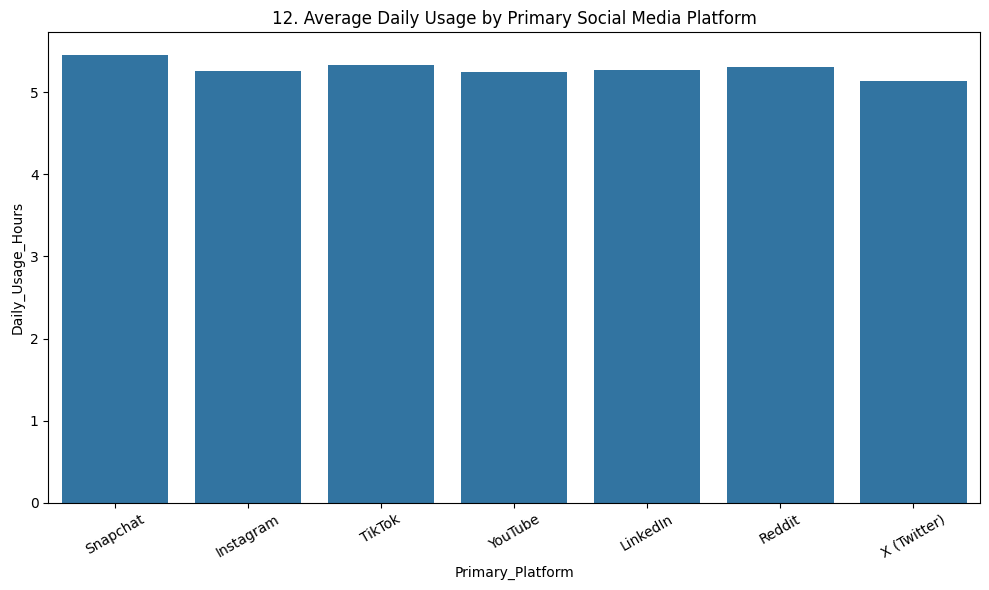

In [25]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Primary_Platform', y='Daily_Usage_Hours', estimator='mean', errorbar=None)
plt.xticks(rotation=30)
plt.title(f'{plot_no}. Average Daily Usage by Primary Social Media Platform')
show_fig()
plot_no += 1

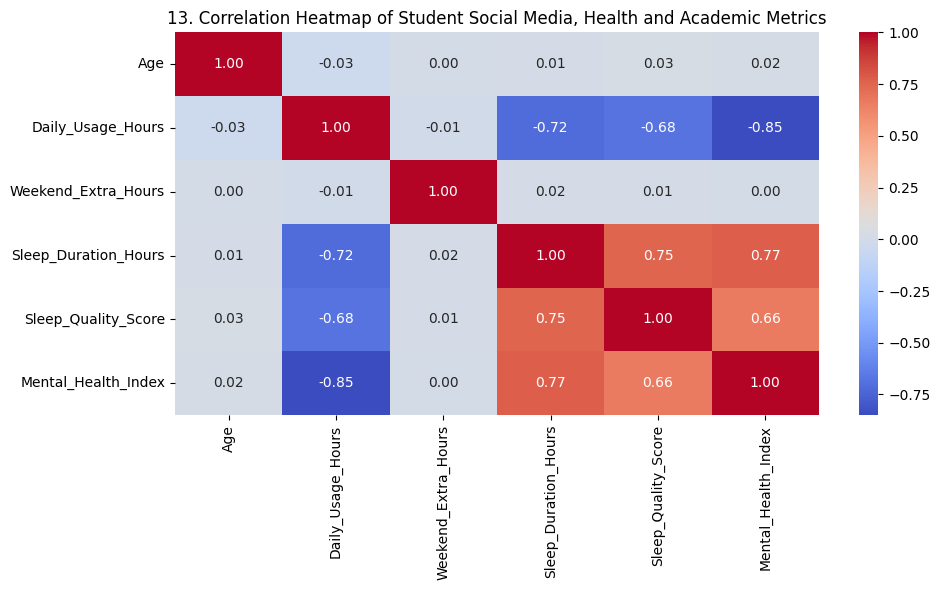

In [26]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title(f'{plot_no}. Correlation Heatmap of Student Social Media, Health and Academic Metrics')
show_fig()
plot_no += 1

> ### 🔎 Analyse critique — Heatmap de corrélation
>
> ❌ La heatmap ne contient que **6 variables** : `Perceived_Stress_Score` et `Academic_Performance_GPA` ont été exclues par `select_dtypes(include='number')`, car le bug d'imputation les a transformées en type `object`. La **cible** n'y figure pas non plus.
>
> ⚠️ Aucun commentaire alors que la heatmap montre des **corrélations très fortes** entre variables explicatives (usage quotidien ↔ santé mentale ≈ −0,85, usage ↔ sommeil ≈ −0,72) : il y a de la **multicolinéarité**, ce qui compte pour interpréter un modèle linéaire et pour la sélection de variables.
>
> Heatmap complète (avec la cible) : Partie 2, section 2.5.

# Model Training

## Prepare features and binary target

In [27]:
data = df.copy()

data = data.drop(columns=['Student_ID'])

data['Late_Night_Usage'] = data['Late_Night_Usage'].astype(int)

data['Overall_Impact'] = data['Overall_Impact'].map({
    'Beneficial': 1,
    'Neutral': 0,
    'Harmful': 0
})

data = pd.get_dummies(
    data,
    columns=[
        'Gender',
        'Academic_Level',
        'Primary_Platform',
        'Device_Type',
        'Social_Comparison_Frequency'
    ],
    drop_first=True
)

data = data.apply(pd.to_numeric, errors='coerce')
data = data.dropna()

X = data.drop(columns=['Overall_Impact'])
y = data['Overall_Impact'].astype(int)

> ### 🔎 Analyse critique — ❌ BUG MAJEUR — encodage de la cible + transformation
>
> **1. Mauvaise modalité dans le mapping**
> ```python
> data['Overall_Impact'].map({'Beneficial': 1, 'Neutral': 0, 'Harmful': 0})
> ```
> La cible contient `Beneficial` (3 681), `Neutral` (654) et **`Negative`** (165), pas `Harmful`. Avec `.map()`, toute modalité absente du dictionnaire devient **NaN** → les 165 étudiants « Negative » sont ensuite supprimés par `dropna()`.
>
> **2. `to_numeric(errors='coerce')` + `dropna()` masquent les erreurs**
> Ces deux lignes forcent tout en numérique et suppriment ce qui ne passe pas, **sans rien afficher**. En rejouant le code : 4 500 → **4 207 lignes**, soit **293 lignes perdues (6,5 %)** : les 165 « Negative » + 128 lignes qui devaient être imputées. Le modèle n'a donc **jamais vu un seul étudiant pour qui l'impact est négatif**, c'est-à-dire précisément les cas les plus importants à détecter.
> Bonne pratique : toujours vérifier la taille avant/après (`assert`, `print(data.shape)`).
>
> **3. Choix de la cible binaire non justifié**
> Regrouper Neutral + Negative en « non bénéfique » peut se défendre, mais il faut le justifier et regarder ce que ça donne pour chaque classe. Le multiclasse n'est jamais envisagé.
>
> **4. Transformation**
> - ⚠️ `Social_Comparison_Frequency` est **ordinale** : un encodage ordinal (0 → 4) conserve l'ordre et évite 4 colonnes one-hot ;
> - ⚠️ l'encodage est fait sur tout le jeu de données **avant** le split et hors `Pipeline` → pas réutilisable en validation croisée ni en production (une modalité nouvelle ferait planter le modèle) ;
> - ✅ `drop_first=True` et la suppression de `Student_ID` sont de bons réflexes.
>
> ✔️ Correction : Partie 2, sections 3 et 4.

## Split the dataset

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

> ### 🔎 Analyse critique — Découpage train/test
>
> ✅ `stratify=y` et `random_state` : bonnes pratiques, les proportions de classes sont conservées.
>
> ❌ Mais c'est **le seul découpage** de tout le notebook : le score dépend de ce tirage précis. Une **validation croisée** (ex. `StratifiedKFold` à 5 plis) est nécessaire pour estimer la performance et sa variabilité (moyenne ± écart-type). Voir Partie 2, section 5.

## Scale numerical features

In [29]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

> ### 🔎 Analyse critique — Standardisation
>
> ✅ **Bien fait** : le `StandardScaler` est ajusté (`fit`) sur le train uniquement, puis appliqué au test. Pas de fuite de données à cette étape.
>
> ⚠️ Remarques :
> - les colonnes one-hot (0/1) sont aussi standardisées ; ce n'est pas faux pour un réseau de neurones, mais c'est inutile et moins lisible ;
> - les transformations sont éparpillées dans plusieurs cellules au lieu d'un `Pipeline` / `ColumnTransformer`, ce qui empêche de les rejouer correctement dans chaque pli d'une validation croisée.

## Build the deep learning model

In [30]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

I0000 00:00:1789640673.035404      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789640673.038440      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


> ### 🔎 Analyse critique — Choix du modèle
>
> ❌ **Aucun modèle de référence (baseline)** : il faut toujours commencer par un modèle trivial (classe majoritaire → 84,9 % d'accuracy ici) puis un modèle simple (régression logistique) avant un réseau de neurones. Sans comparaison, on ne sait pas si la complexité est utile.
> → En Partie 2, une régression logistique fait **aussi bien ou mieux** que ce réseau.
>
> ⚠️ Architecture (32 → 16 → 1, dropout 0,2) non justifiée et jamais optimisée. Le titre du notebook annonce « 1057 parameters », mais avec 26 variables d'entrée cette architecture compte **1 409 paramètres** (26×32+32 + 32×16+16 + 16+1). `model.summary()` n'est jamais appelé pour le vérifier.
>
> ⚠️ Pas de `tf.random.set_seed` → résultats non reproductibles.

## Train the deep learning model

In [31]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
72/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7093 - loss: 0.5654

I0000 00:00:1789640677.397120      73 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.8310 - loss: 0.4330 - val_accuracy: 0.9168 - val_loss: 0.2757
Epoch 2/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9350 - loss: 0.2146 - val_accuracy: 0.9510 - val_loss: 0.1708
Epoch 3/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9428 - loss: 0.1506 - val_accuracy: 0.9554 - val_loss: 0.1278
Epoch 4/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9614 - loss: 0.1140 - val_accuracy: 0.9599 - val_loss: 0.1035
Epoch 5/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9610 - loss: 0.0950 - val_accuracy: 0.9629 - val_loss: 0.0916
Epoch 6/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9681 - loss: 0.0836 - val_accuracy: 0.9643 - val_loss: 0.0853
Epoch 7/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9725 - loss: 0.0726 - val_accuracy: 0.9629 - val_loss: 0.0809
Epoch 8/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9762 - loss: 0.0688 - val_accuracy: 0.9673 - val_loss: 0.0715
Ep

> ### 🔎 Analyse critique — Entraînement
>
> ❌ **Pas de validation croisée** : `validation_split=0.2` est un simple *hold-out* (les 20 % **derniers** échantillons du train, toujours les mêmes). C'est utile pour suivre l'entraînement, mais ce n'est pas une validation croisée.
>
> ⚠️ 50 epochs fixées arbitrairement, **sans `EarlyStopping`** : dans les logs ci-dessus, `val_loss` atteint son minimum (≈ 0,056) vers l'epoch 25 puis remonte (≈ 0,066–0,075), alors que la loss d'entraînement continue de baisser (0,024 → 0,012). C'est le signe classique d'un **début de sur-apprentissage** : les 25 dernières epochs n'apportent rien.
>
> ⚠️ L'objet `history` est récupéré mais **jamais exploité** : les courbes loss/accuracy (train vs validation) auraient dû être tracées pour diagnostiquer sur- ou sous-apprentissage. Voir les courbes d'apprentissage en Partie 2, section 6.4.
>
> ⚠️ Aucun réglage des hyperparamètres (taux d'apprentissage, taille des couches, dropout, batch size).

## Calculate model accuracy

In [32]:
y_prob = model.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int).ravel()

accuracy = accuracy_score(y_test, y_pred)

print(f'Model Accuracy: {accuracy:.4f}')

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Model Accuracy: 0.9834


> ### 🔎 Analyse critique — Évaluation — accuracy
>
> ❌ **L'accuracy seule est trompeuse sur des classes déséquilibrées.** Sur les données de l'auteur, 84,9 % des étudiants sont « Beneficial » : un modèle qui répond toujours « Beneficial » obtient déjà **84,9 %**. Les 98,3 % doivent être comparés à ce chiffre, pas à 50 %.
>
> Il manque :
> - **précision, rappel et F1 par classe** (`classification_report`), surtout pour la classe minoritaire ;
> - **balanced accuracy** et **ROC-AUC** ;
> - l'écart-type du score (impossible sans validation croisée).
>
> ⚠️ Le seuil de 0,5 est utilisé sans discussion : s'il est plus grave de rater un étudiant pour qui l'impact n'est pas bénéfique, on pourrait abaisser ce seuil (courbe précision-rappel).

## Plot the confusion matrix

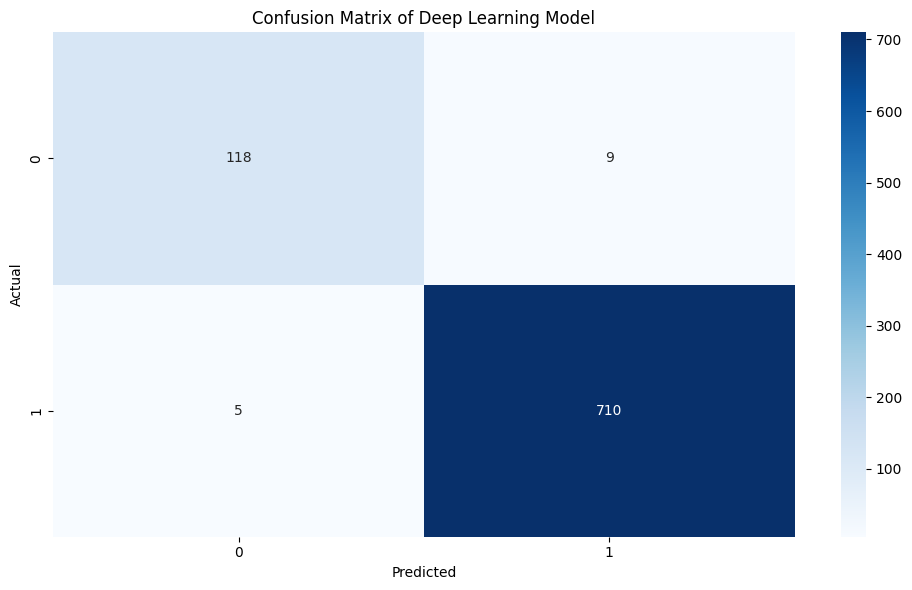

In [33]:
fig = plt.figure(figsize=(10,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix of Deep Learning Model')
show_fig()
plot_no += 1

> ### 🔎 Analyse critique — Évaluation — matrice de confusion
>
> ✅ Bonne idée de tracer la matrice de confusion.
>
> ⚠️ Mais elle n'est **ni normalisée ni commentée** (combien d'étudiants « non bénéfiques » sont ratés ?), et les axes ne portent pas les noms des classes (0/1 au lieu de « Non bénéfique » / « Bénéfique »).
>
> ❌ Il manque toute **interprétation du modèle** : quelles variables comptent le plus ? Le modèle est-il cohérent avec l'EDA ? Et la question de fond : la cible `Overall_Impact` semble construite à partir du stress, de la santé mentale et du GPA, qui sont **eux-mêmes des variables d'entrée** → le score très élevé est en partie mécanique (voir Partie 2, section 6.7).
>
> *(`plot_no += 1` ici ne sert à rien : ce graphique n'est pas numéroté.)*

---
---
# Partie 2 — Compléments et corrections de la pipeline

Cette partie reprend la pipeline **depuis le CSV brut** (pour ne pas hériter des bugs de la Partie 1) et ajoute les étapes manquantes :

| Section | Étape de la pipeline | Ce qui est ajouté / corrigé |
|---|---|---|
| 1 | Data | Définition du problème et de la cible |
| 2 | EDA | Cible, cible ↔ variables, catégorielles, corrélations complètes, outliers, cohérence, valeurs manquantes |
| 3 | Prétraitement | Encodage correct de la cible, découpage train/test **avant** toute transformation |
| 4 | Transformation | `Pipeline` + `ColumnTransformer` : imputation, standardisation, encodage ordinal et one-hot |
| 5 | ML | Baseline, comparaison de 5 modèles en **validation croisée stratifiée à 5 plis**, réglage d'hyperparamètres (`GridSearchCV`) |
| 6 | Évaluation | Rapport de classification, matrice de confusion, ROC / précision-rappel, courbes d'apprentissage, importance des variables, multiclasse, analyse critique de la cible |

> **Pourquoi scikit-learn et pas Keras ?** La validation croisée et le réglage d'hyperparamètres sont beaucoup plus simples avec les `Pipeline` scikit-learn. Le réseau de l'auteur (32 → 16 → 1, ReLU) est reproduit avec `MLPClassifier(hidden_layer_sizes=(32, 16))`, ce qui permet de le comparer équitablement aux autres modèles.


## 0. Imports et reproductibilité

In [34]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, accuracy_score, balanced_accuracy_score,
                             f1_score, roc_auc_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')

# Graine fixée partout -> résultats reproductibles (absent du notebook d'origine)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Chemin Kaggle, avec repli sur un fichier local pour que le notebook tourne ailleurs
CSV_PATH = '/kaggle/input/datasets/harishyadav0506/impact-of-social-media-on-life/Social_media_impact_on_life.csv'
if not os.path.exists(CSV_PATH):
    CSV_PATH = 'Social_media_impact_on_life.csv'

raw = pd.read_csv(CSV_PATH)
print('Dimensions :', raw.shape)

Dimensions : (4500, 16)


## 1. Data — définition du problème *(étape absente du notebook d'origine)*

- **Objectif** : prédire l'impact global des réseaux sociaux sur un étudiant (`Overall_Impact`) à partir de ses habitudes d'usage, de son profil et d'indicateurs de bien-être.
- **Type de tâche** : classification supervisée.
- **Variable cible** : `Overall_Impact`, 3 modalités : `Beneficial`, `Neutral`, `Negative` (et **pas** `Harmful` comme l'a supposé l'auteur).
- **Choix de modélisation** : on garde le choix de l'auteur, *bénéfique (1) vs non bénéfique (0 = Neutral + Negative)*, **mais correctement encodé**, pour pouvoir comparer les résultats. On teste aussi la version **à 3 classes** (section 6.6), qui est plus informative.
- **Variables explicatives** (14 après suppression de l'identifiant) :

| Type | Variables |
|---|---|
| Numériques continues | `Age`, `Daily_Usage_Hours`, `Weekend_Extra_Hours`, `Sleep_Duration_Hours`, `Perceived_Stress_Score` (0–40), `Mental_Health_Index` (0–100), `Academic_Performance_GPA` (0–4) |
| Ordinales | `Sleep_Quality_Score` (1–5), `Social_Comparison_Frequency` (Never → Always) |
| Binaire | `Late_Night_Usage` |
| Nominales | `Gender`, `Academic_Level`, `Primary_Platform`, `Device_Type` |
| À supprimer | `Student_ID` (identifiant, aucune information) |


## 2. EDA complémentaire
### 2.1 Distribution de la variable cible *(manquant)*

,effectif,%
Overall_Impact,,
Beneficial,3681,81.8
Neutral,654,14.5
Negative,165,3.7


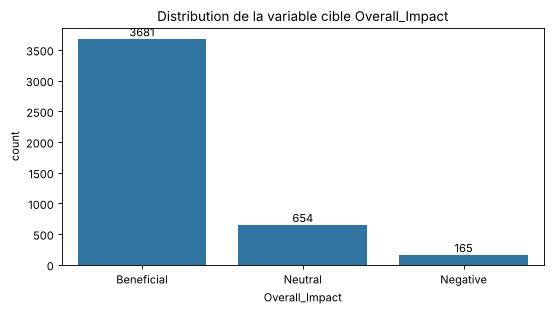

In [35]:
ORDER = ['Beneficial', 'Neutral', 'Negative']
tab = pd.DataFrame({'effectif': raw['Overall_Impact'].value_counts(),
                    '%': raw['Overall_Impact'].value_counts(normalize=True).mul(100).round(1)}).loc[ORDER]
display(tab)

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=raw, x='Overall_Impact', order=ORDER, ax=ax)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
ax.set_title('Distribution de la variable cible Overall_Impact')
plt.tight_layout(); plt.show()

**Interprétation.**
- La cible est **fortement déséquilibrée** : 81,8 % *Beneficial*, 14,5 % *Neutral*, **3,7 % *Negative*** (165 étudiants).
- La modalité s'appelle bien `Negative` : le mapping de l'auteur (`'Harmful'`) ne pouvait donc pas fonctionner.
- En binaire (bénéfique / non bénéfique), la classe minoritaire représente 18,2 %. Un modèle qui répond toujours « Beneficial » a donc **81,8 % d'accuracy** sans rien apprendre (84,9 % sur les données amputées de l'auteur).
- ➜ Conséquences pour la suite : découpage **stratifié**, validation croisée **stratifiée**, et métriques adaptées au déséquilibre (**balanced accuracy, F1 macro, ROC-AUC**), pas l'accuracy seule.

### 2.2 Variables catégorielles : modalités et effectifs *(manquant)*

In [36]:
cat_cols = ['Gender', 'Academic_Level', 'Primary_Platform', 'Device_Type',
            'Social_Comparison_Frequency', 'Late_Night_Usage']
for c in cat_cols:
    vc = raw[c].value_counts(normalize=True).mul(100).round(1)
    print(f'{c:<28}', dict(vc))
print('\nStudent_ID unique pour chaque ligne :', raw['Student_ID'].is_unique)

Gender                       {'Female': np.float64(49.6), 'Male': np.float64(45.6), 'Non-Binary': np.float64(2.7), 'Prefer not to say': np.float64(2.1)}
Academic_Level               {'Undergraduate': np.float64(61.7), 'High School': np.float64(32.8), 'Postgraduate': np.float64(5.5)}
Primary_Platform             {'Instagram': np.float64(32.3), 'TikTok': np.float64(27.2), 'YouTube': np.float64(18.2), 'Snapchat': np.float64(10.5), 'Reddit': np.float64(5.1), 'X (Twitter)': np.float64(4.6), 'LinkedIn': np.float64(2.1)}
Device_Type                  {'Smartphone': np.float64(83.9), 'Laptop/PC': np.float64(13.2), 'Tablet': np.float64(2.9)}
Social_Comparison_Frequency  {'Sometimes': np.float64(35.4), 'Frequently': np.float64(27.7), 'Rarely': np.float64(17.0), 'Always': np.float64(14.0), 'Never': np.float64(5.8)}
Late_Night_Usage             {True: np.float64(58.8), False: np.float64(41.2)}

Student_ID unique pour chaque ligne : True


**Interprétation.**
- Les modalités sont propres : pas de fautes de frappe ni de doublons de catégories (ex. « female » / « Female »). `Student_ID` est bien unique.
- Plusieurs **modalités rares** (< 3 %) : `Non-Binary`, `Prefer not to say`, `LinkedIn`, `Tablet`. Avec le one-hot, ces colonnes contiennent très peu de 1 : leurs coefficients seront peu fiables. Un regroupement (« Other ») serait envisageable.
- `Social_Comparison_Frequency` a un **ordre naturel** → encodage ordinal (section 4).

### 2.3 Cible ↔ variables numériques *(manquant)*

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
Overall_Impact,,,,,,,,
Beneficial,19.0,4.2,1.8,7.0,3.0,11.0,85.0,3.55
Neutral,18.0,8.4,1.8,5.5,1.0,22.0,64.0,2.99
Negative,18.0,12.4,1.8,4.1,1.0,31.0,47.0,2.55


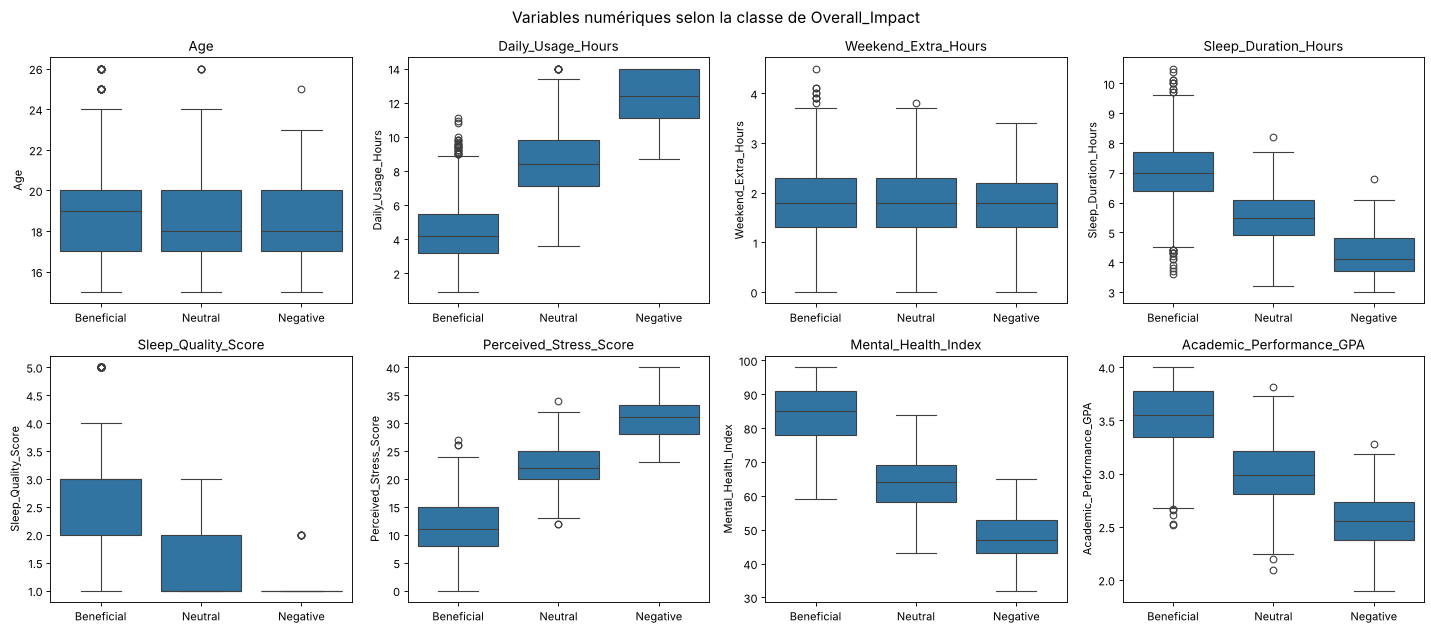

In [37]:
num_cols = ['Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Sleep_Duration_Hours',
            'Sleep_Quality_Score', 'Perceived_Stress_Score', 'Mental_Health_Index',
            'Academic_Performance_GPA']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=raw, x='Overall_Impact', y=col, order=ORDER, ax=ax)
    ax.set_title(col); ax.set_xlabel('')
fig.suptitle('Variables numériques selon la classe de Overall_Impact', fontsize=14)
plt.tight_layout(); plt.show()

display(raw.groupby('Overall_Impact')[num_cols].median().loc[ORDER].round(2))

**Interprétation.**
- Les classes sont **très bien séparées** par 6 variables : usage quotidien (médiane croissante de *Beneficial* à *Negative*), durée et qualité du sommeil, stress perçu, indice de santé mentale et GPA (décroissants).
- Les étudiants *Negative* forment un groupe extrême : beaucoup d'heures d'écran, peu de sommeil, stress élevé, santé mentale et GPA faibles. *Neutral* est entre les deux.
- `Age` et `Weekend_Extra_Hours` ne différencient pas les classes → probablement peu utiles au modèle.
- ➜ Une séparation aussi nette laisse prévoir des scores très élevés, même avec un modèle simple (ce que confirme la section 5).

### 2.4 Cible ↔ variables catégorielles *(manquant)*

Overall_Impact,Beneficial,Neutral,Negative
Social_Comparison_Frequency,,,
Never,83.8,12.3,3.8
Rarely,81.1,14.0,5.0
Sometimes,82.0,14.9,3.1
Frequently,82.0,14.6,3.4
Always,81.0,15.0,4.0


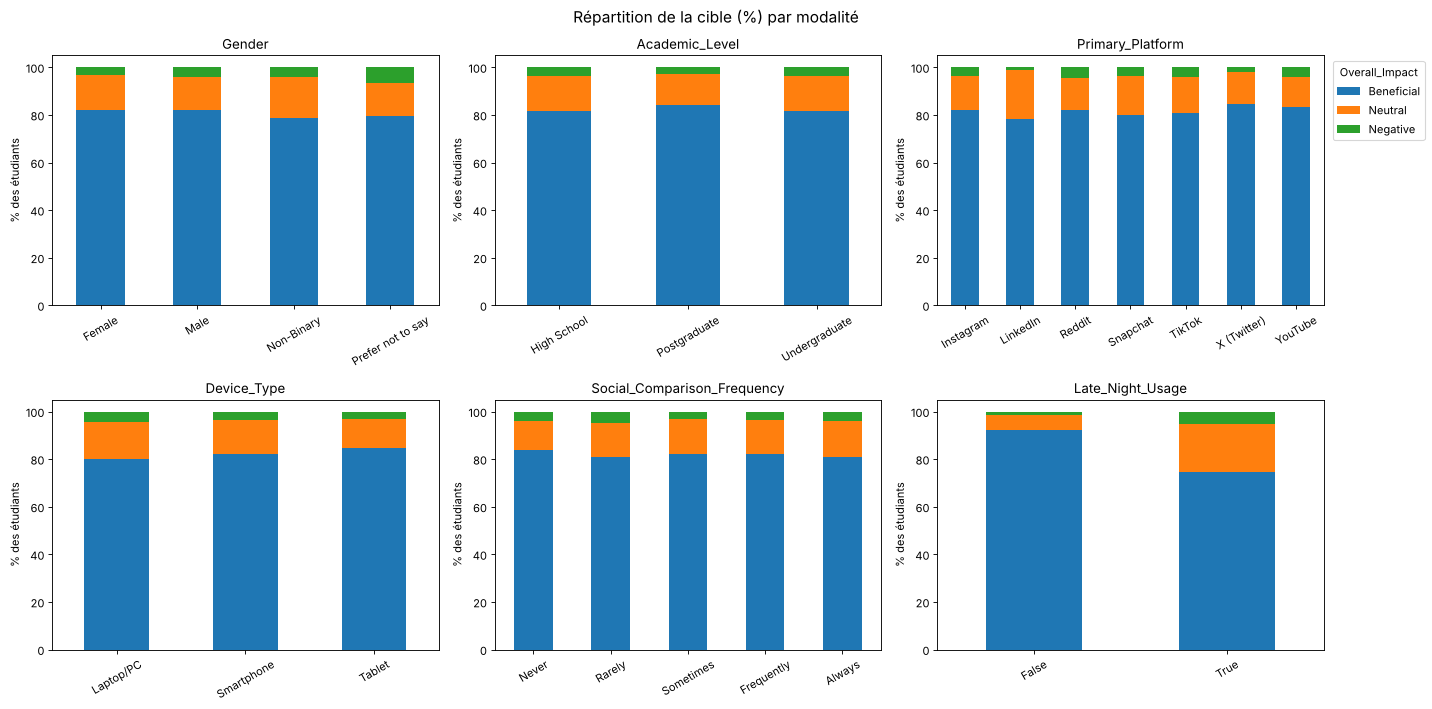

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    ct = pd.crosstab(raw[col], raw['Overall_Impact'], normalize='index')[ORDER] * 100
    if col == 'Social_Comparison_Frequency':
        ct = ct.loc[['Never', 'Rarely', 'Sometimes', 'Frequently', 'Always']]
    ct.plot(kind='bar', stacked=True, ax=ax, legend=False)
    ax.set_title(col); ax.set_ylabel('% des étudiants'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
axes[0, 2].legend(title='Overall_Impact', bbox_to_anchor=(1.01, 1), loc='upper left')
fig.suptitle('Répartition de la cible (%) par modalité', fontsize=14)
plt.tight_layout(); plt.show()

ct_sc = pd.crosstab(raw['Social_Comparison_Frequency'], raw['Overall_Impact'], normalize='index')
display((ct_sc.loc[['Never', 'Rarely', 'Sometimes', 'Frequently', 'Always'], ORDER] * 100).round(1))

**Interprétation.**
- **`Late_Night_Usage` est la seule variable catégorielle vraiment discriminante** : 92,1 % de *Beneficial* chez ceux qui n'utilisent pas les réseaux la nuit, contre 74,5 % chez ceux qui le font (et 3 fois plus de *Negative* : 5,1 % contre 1,6 %).
- Pour la plateforme, le genre, l'appareil et le niveau d'études, la répartition reste autour de 80 / 15 / 4 % : ces variables apportent peu d'information.
- Résultat contre-intuitif : la **fréquence de comparaison sociale n'a quasiment aucun lien avec la cible** (81–84 % de *Beneficial* quelle que soit la modalité), alors que le graphique 10 de l'auteur la mettait en avant. C'est le genre de constat qu'une EDA doit faire avant de modéliser.

### 2.5 Matrice de corrélation complète, avec la cible *(corrigée)*

Corrélation avec la cible (Beneficial = 1) :
Mental_Health_Index         0.72
Daily_Usage_Hours          -0.72
Perceived_Stress_Score     -0.71
Academic_Performance_GPA    0.63
Sleep_Duration_Hours        0.58
Sleep_Quality_Score         0.51
Late_Night_Usage           -0.22
Age                         0.03
Weekend_Extra_Hours         0.01
Social_Comparison          -0.01


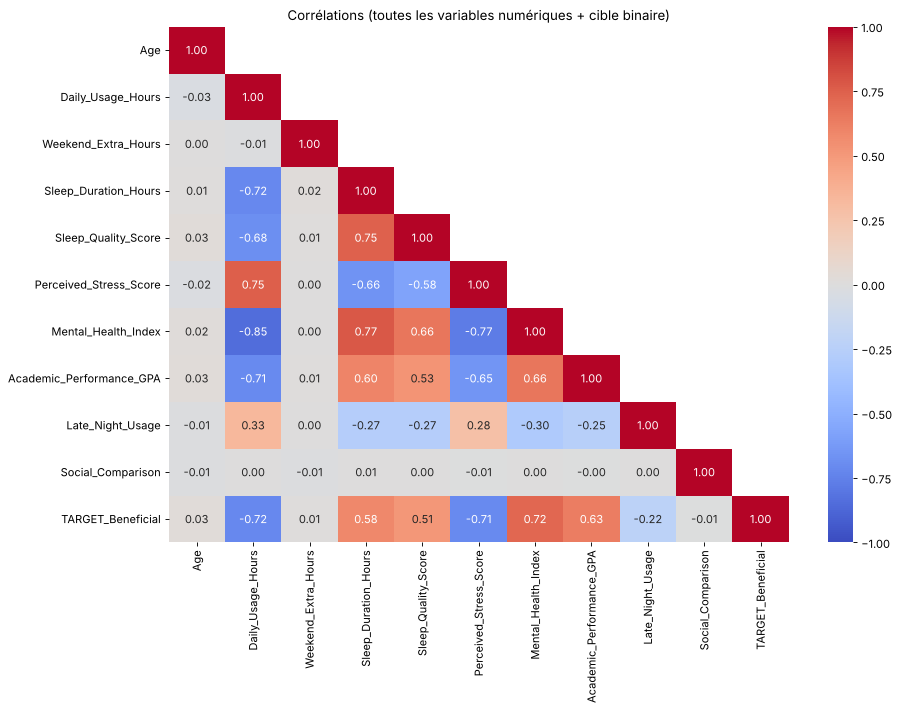

In [39]:
corr_df = raw[num_cols].copy()
corr_df['Late_Night_Usage'] = raw['Late_Night_Usage'].astype(int)
corr_df['Social_Comparison'] = raw['Social_Comparison_Frequency'].map(
    {'Never': 0, 'Rarely': 1, 'Sometimes': 2, 'Frequently': 3, 'Always': 4})
corr_df['TARGET_Beneficial'] = (raw['Overall_Impact'] == 'Beneficial').astype(int)

corr = corr_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Corrélations (toutes les variables numériques + cible binaire)')
plt.tight_layout(); plt.show()

print('Corrélation avec la cible (Beneficial = 1) :')
print(corr['TARGET_Beneficial'].drop('TARGET_Beneficial').sort_values(key=abs, ascending=False).round(2).to_string())

**Interprétation.**
- Les variables les plus corrélées à la cible sont la santé mentale (+0,72), l'usage quotidien (−0,72), le stress (−0,71), le GPA (+0,63) et le sommeil (+0,58 / +0,51). Le stress et le GPA, absents de la heatmap de l'auteur, font partie des plus importantes.
- **Forte multicolinéarité** : usage quotidien, sommeil, stress, santé mentale et GPA sont tous corrélés entre eux (|r| entre 0,5 et 0,85). Ces variables portent en grande partie la même information. Pour un modèle linéaire, cela rend les coefficients individuels instables et difficiles à interpréter ; une régularisation (paramètre `C` de la régression logistique) est utile.
- `Age`, `Weekend_Extra_Hours` et `Social_Comparison` ont une corrélation quasi nulle avec la cible.

### 2.6 Valeurs aberrantes et cohérence des données *(manquant)*

In [40]:
q1, q3 = raw[num_cols].quantile(0.25), raw[num_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((raw[num_cols] < q1 - 1.5 * iqr) | (raw[num_cols] > q3 + 1.5 * iqr)).sum()
display(pd.DataFrame({'min': raw[num_cols].min(), 'max': raw[num_cols].max(),
                      'nb outliers (règle IQR)': outliers,
                      '% outliers': (outliers / len(raw) * 100).round(1)}))

# Cohérence âge / niveau d'études
display(pd.crosstab(raw['Age'], raw['Academic_Level']))

,min,max,nb outliers (règle IQR),% outliers
Age,15.0,26.0,51,1.1
Daily_Usage_Hours,0.9,14.0,162,3.6
Weekend_Extra_Hours,0.0,4.5,10,0.2
Sleep_Duration_Hours,3.0,10.5,72,1.6
Sleep_Quality_Score,1.0,5.0,91,2.0
Perceived_Stress_Score,0.0,40.0,75,1.7
Mental_Health_Index,32.0,98.0,85,1.9
Academic_Performance_GPA,1.9,4.0,68,1.5


Academic_Level,High School,Postgraduate,Undergraduate
Age,,,
15,164,0,0
16,340,0,0
17,716,0,0
18,101,0,927
19,74,0,828
20,52,0,578
21,30,0,326
22,0,122,56
23,0,53,32


**Interprétation.**
- La règle de l'IQR signale entre 0,2 % et 3,6 % de valeurs « atypiques » selon les variables, mais **toutes les valeurs restent plausibles** : 14 h d'écran par jour (max), 3 h de sommeil, stress de 0 à 40 (bornes exactes de l'échelle PSS-10), GPA entre 1,9 et 4,0, âge de 15 à 26 ans.
- Ce ne sont donc **pas des erreurs de saisie** mais des cas extrêmes réels, souvent les étudiants *Negative* qu'on cherche justement à détecter. ➜ **On les garde** (les supprimer retirerait une partie de la classe minoritaire). La standardisation et la régularisation suffisent à limiter leur influence.
- **Cohérence âge / niveau** : les *Postgraduate* ont tous 22 ans ou plus, les *High School* entre 15 et 21 ans. 82 lycéens de 20–21 ans, c'est inhabituel mais possible (redoublement, systèmes scolaires différents). Aucune incohérence flagrante.

### 2.7 Mécanisme des valeurs manquantes *(manquant)*

In [41]:
miss = raw[['Perceived_Stress_Score', 'Academic_Performance_GPA']].isna()
display((miss.groupby(raw['Overall_Impact']).mean() * 100).round(2).loc[ORDER]
        .rename(columns=lambda c: f'% manquants {c}'))
print('Lignes avec au moins une valeur manquante :', miss.any(axis=1).sum(),
      f'({miss.any(axis=1).mean()*100:.1f} %)')
print('Lignes avec les deux manquantes :', miss.all(axis=1).sum())

,% manquants Perceived_Stress_Score,% manquants Academic_Performance_GPA
Overall_Impact,,
Beneficial,1.03,1.93
Neutral,1.07,1.83
Negative,0.61,1.21


Lignes avec au moins une valeur manquante : 131 (2.9 %)
Lignes avec les deux manquantes : 0


**Interprétation.**
- 131 lignes (2,9 %) ont une valeur manquante, jamais les deux en même temps.
- Le taux de valeurs manquantes est **similaire dans les trois classes** (≈ 1 % pour le stress, ≈ 2 % pour le GPA) : les manquants semblent **aléatoires** et non liés à la cible.
- ➜ Une **imputation par la médiane** est raisonnable. Supprimer les lignes (ce que fait le notebook d'origine sans le vouloir) ferait perdre 2,9 % des données sans raison.

### 2.8 Synthèse de l'EDA

| Constat | Conséquence pour la pipeline |
|---|---|
| Cible déséquilibrée (81,8 / 14,5 / 3,7 %) | Stratification, balanced accuracy / F1 macro / ROC-AUC, baseline obligatoire |
| Cible = `Negative` et non `Harmful` | Mapping explicite + contrôle par `assert` |
| 2,9 % de manquants, aléatoires | Imputation par la médiane, dans le `Pipeline` |
| Outliers plausibles | Conservés |
| Variable ordinale (`Social_Comparison_Frequency`) | Encodage ordinal |
| Modalités rares | One-hot avec `handle_unknown='ignore'` |
| 6 variables très discriminantes et très corrélées entre elles | Régularisation ; on s'attend à des scores élevés même avec un modèle linéaire |
| Plateforme, genre, appareil, âge, comparaison sociale peu liés à la cible | Peu d'importance attendue (vérifié en 6.5) |

## 3. Prétraitement corrigé

Corrections par rapport au notebook d'origine :
1. **Encodage explicite de la cible** avec un contrôle (`assert`) : aucune ligne ne peut disparaître en silence ;
2. **Aucune suppression de lignes** : les valeurs manquantes seront imputées (médiane) ;
3. **Découpage train/test en premier**, stratifié sur les **3 classes** (pour garder la même proportion de « Negative » dans le train et le test) ; l'imputation et la standardisation seront apprises **sur le train uniquement**, dans le `Pipeline` (section 4).

In [42]:
df = raw.drop(columns=['Student_ID']).copy()
df['Late_Night_Usage'] = df['Late_Night_Usage'].astype(int)

y_multi = df.pop('Overall_Impact')
assert set(y_multi.unique()) == {'Beneficial', 'Neutral', 'Negative'}, y_multi.unique()

# Cible binaire de l'auteur, mais correcte : 1 = Beneficial, 0 = Neutral OU Negative
y_bin = (y_multi == 'Beneficial').astype(int)
X = df
assert len(X) == len(raw)   # aucune ligne perdue

X_train, X_test, y_train, y_test, ym_train, ym_test = train_test_split(
    X, y_bin, y_multi, test_size=0.2, stratify=y_multi, random_state=SEED)

print('Train :', X_train.shape, '| Test :', X_test.shape)
print('Proportion de non-bénéfiques  train / test :',
      round(1 - y_train.mean(), 3), '/', round(1 - y_test.mean(), 3))
print('Effectif "Negative"  train / test :', (ym_train == 'Negative').sum(), '/', (ym_test == 'Negative').sum())
print('\nComparaison avec l\'auteur : 4 207 lignes et 0 "Negative"  ->  ici', len(X), 'lignes et',
      (y_multi == 'Negative').sum(), '"Negative"')

Train : (3600, 14) | Test : (900, 14)
Proportion de non-bénéfiques  train / test : 0.182 / 0.182
Effectif "Negative"  train / test : 132 / 33

Comparaison avec l'auteur : 4 207 lignes et 0 "Negative"  ->  ici 4500 lignes et 165 "Negative"


## 4. Transformation : `Pipeline` + `ColumnTransformer`

Chaque type de variable reçoit la transformation adaptée, et **tout est encapsulé dans un objet unique** qui est ré-ajusté sur le train de chaque pli de la validation croisée → aucune fuite de données.

| Groupe | Transformation |
|---|---|
| Numériques (+ `Late_Night_Usage`, `Sleep_Quality_Score`) | imputation par la **médiane** → `StandardScaler` |
| Ordinale `Social_Comparison_Frequency` | `OrdinalEncoder` avec l'ordre Never < Rarely < Sometimes < Frequently < Always, puis `StandardScaler` |
| Nominales | `OneHotEncoder(handle_unknown='ignore')` (une modalité inconnue ne fait plus planter le modèle) |


In [43]:
NUM = ['Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Sleep_Duration_Hours',
       'Sleep_Quality_Score', 'Perceived_Stress_Score', 'Mental_Health_Index',
       'Academic_Performance_GPA', 'Late_Night_Usage']
ORD = ['Social_Comparison_Frequency']
NOM = ['Gender', 'Academic_Level', 'Primary_Platform', 'Device_Type']
SC_ORDER = [['Never', 'Rarely', 'Sometimes', 'Frequently', 'Always']]

def make_preprocessor(num=NUM, ord_=ORD, nom=NOM):
    return ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), num),
        ('ord', Pipeline([('encoder', OrdinalEncoder(categories=SC_ORDER)),
                          ('scaler', StandardScaler())]), ord_),
        ('nom', OneHotEncoder(handle_unknown='ignore'), nom),
    ])

pre = make_preprocessor()
Xt = pre.fit_transform(X_train)
print('Matrice transformée :', Xt.shape, '| NaN restants :', int(np.isnan(np.asarray(Xt, dtype=float)).sum()))
print(list(pre.get_feature_names_out()))

Matrice transformée : (3600, 27) | NaN restants : 0
['num__Age', 'num__Daily_Usage_Hours', 'num__Weekend_Extra_Hours', 'num__Sleep_Duration_Hours', 'num__Sleep_Quality_Score', 'num__Perceived_Stress_Score', 'num__Mental_Health_Index', 'num__Academic_Performance_GPA', 'num__Late_Night_Usage', 'ord__Social_Comparison_Frequency', 'nom__Gender_Female', 'nom__Gender_Male', 'nom__Gender_Non-Binary', 'nom__Gender_Prefer not to say', 'nom__Academic_Level_High School', 'nom__Academic_Level_Postgraduate', 'nom__Academic_Level_Undergraduate', 'nom__Primary_Platform_Instagram', 'nom__Primary_Platform_LinkedIn', 'nom__Primary_Platform_Reddit', 'nom__Primary_Platform_Snapchat', 'nom__Primary_Platform_TikTok', 'nom__Primary_Platform_X (Twitter)', 'nom__Primary_Platform_YouTube', 'nom__Device_Type_Laptop/PC', 'nom__Device_Type_Smartphone', 'nom__Device_Type_Tablet']


## 5. Modélisation avec validation croisée

### 5.1 Comparaison de modèles *(baseline + 4 modèles, absents du notebook d'origine)*

- **Validation croisée stratifiée à 5 plis** (`StratifiedKFold`), réalisée **sur le train uniquement** : le test reste intact pour l'évaluation finale.
- **Plusieurs métriques**, car les classes sont déséquilibrées : accuracy, **balanced accuracy** (moyenne des rappels de chaque classe), **F1 macro**, **ROC-AUC**.
- `DummyClassifier` = baseline (prédit toujours la classe majoritaire).

In [44]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {'accuracy': 'accuracy', 'balanced_acc': 'balanced_accuracy',
           'f1_macro': 'f1_macro', 'roc_auc': 'roc_auc'}

models = {
    'Baseline (classe majoritaire)': DummyClassifier(strategy='most_frequent'),
    'Régression logistique': LogisticRegression(max_iter=2000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'Gradient Boosting (HGB)': HistGradientBoostingClassifier(random_state=SEED),
    'MLP 32-16 (≈ réseau de l\'auteur)': MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=1000,
                                                     early_stopping=True, random_state=SEED),
}

rows, cv_raw = [], {}
for name, model in models.items():
    pipe = Pipeline([('pre', make_preprocessor()), ('model', model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING)
    cv_raw[name] = res
    rows.append({'Modèle': name, **{f'{m} (moy ± éc.)': f"{res['test_'+m].mean():.3f} ± {res['test_'+m].std():.3f}"
                                     for m in SCORING}})
cv_results = pd.DataFrame(rows).set_index('Modèle')
display(cv_results)

,accuracy (moy ± éc.),balanced_acc (moy ± éc.),f1_macro (moy ± éc.),roc_auc (moy ± éc.)
Modèle,,,,
Baseline (classe majoritaire),0.818 ± 0.000,0.500 ± 0.000,0.450 ± 0.000,0.500 ± 0.000
Régression logistique,0.992 ± 0.003,0.985 ± 0.004,0.986 ± 0.005,0.999 ± 0.000
Random Forest,0.980 ± 0.006,0.961 ± 0.015,0.966 ± 0.011,0.998 ± 0.001
Gradient Boosting (HGB),0.987 ± 0.003,0.976 ± 0.003,0.978 ± 0.005,0.999 ± 0.000
MLP 32-16 (≈ réseau de l'auteur),0.978 ± 0.011,0.959 ± 0.025,0.962 ± 0.019,0.996 ± 0.003


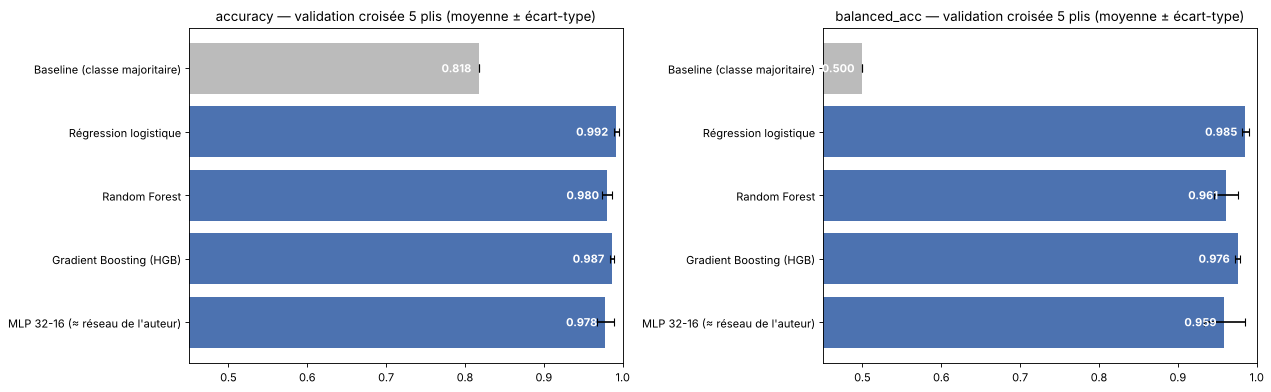

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, m in zip(axes, ['accuracy', 'balanced_acc']):
    names = list(cv_raw)
    means = [cv_raw[n]['test_' + m].mean() for n in names]
    stds = [cv_raw[n]['test_' + m].std() for n in names]
    ax.barh(names, means, xerr=stds, capsize=4, color=['#bbbbbb'] + ['#4C72B0'] * (len(names) - 1))
    ax.set_xlim(0.45, 1.0); ax.set_title(f'{m} — validation croisée 5 plis (moyenne ± écart-type)')
    for i, v in enumerate(means):
        ax.text(v - 0.01, i, f'{v:.3f}', va='center', ha='right', color='white', fontweight='bold')
    ax.invert_yaxis()
plt.tight_layout(); plt.show()

**Interprétation.**
- La **baseline** atteint 0,818 d'accuracy mais seulement **0,500 de balanced accuracy** : elle ne détecte aucun étudiant non bénéfique. C'est le point de comparaison qui manquait dans le notebook d'origine.
- Tous les modèles font beaucoup mieux que la baseline. La **régression logistique** obtient le meilleur score (accuracy ≈ 0,992, ROC-AUC ≈ 0,999) : un modèle **linéaire à ~30 paramètres** fait mieux que le réseau de neurones.
- Le **MLP 32-16** (équivalent du modèle de l'auteur) est le moins bon des 4 modèles et le **plus instable** (écart-type le plus grand d'un pli à l'autre). Sur ce jeu, la complexité d'un réseau de neurones n'apporte rien.
- Les écarts-types (≤ 0,011) montrent que les scores sont stables d'un pli à l'autre : c'est ce que permet de mesurer la validation croisée, et pas un split unique.

### 5.2 Réglage des hyperparamètres (`GridSearchCV`) *(absent du notebook d'origine)*

On règle les deux modèles les plus intéressants : la **régression logistique** (meilleur score, simple et interprétable) et le **MLP** (équivalent du réseau de l'auteur). Critère d'optimisation : **balanced accuracy**, pour ne pas favoriser la classe majoritaire.
La recherche se fait elle aussi en validation croisée à 5 plis sur le train.

In [46]:
grids = {
    'Régression logistique': (
        LogisticRegression(max_iter=5000, random_state=SEED),
        {'model__C': [0.01, 0.1, 1, 10, 100], 'model__class_weight': [None, 'balanced']}),
    'MLP': (
        MLPClassifier(max_iter=1000, early_stopping=True, random_state=SEED),
        {'model__hidden_layer_sizes': [(16,), (32, 16), (64, 32)], 'model__alpha': [1e-4, 1e-2, 1e-1]}),
}

searches = {}
for name, (model, grid) in grids.items():
    gs = GridSearchCV(Pipeline([('pre', make_preprocessor()), ('model', model)]), grid,
                      cv=cv, scoring='balanced_accuracy', n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f'{name:<22} meilleurs paramètres : {gs.best_params_}')
    print(f'{"":<22} balanced accuracy CV : {gs.best_score_:.4f}\n')

best_name = max(searches, key=lambda n: searches[n].best_score_)
best_model = searches[best_name].best_estimator_
print('==> Modèle retenu :', best_name)

Régression logistique  meilleurs paramètres : {'model__C': 10, 'model__class_weight': 'balanced'}
                       balanced accuracy CV : 0.9886

MLP                    meilleurs paramètres : {'model__alpha': 0.1, 'model__hidden_layer_sizes': (64, 32)}
                       balanced accuracy CV : 0.9770

==> Modèle retenu : Régression logistique


**Interprétation.**
- Régression logistique : la meilleure configuration est `C = 10` (régularisation faible) avec `class_weight='balanced'`, qui donne plus de poids à la classe minoritaire. Balanced accuracy en CV : **0,989**.
- MLP : le meilleur réseau est plus large (64-32) et plus régularisé (`alpha = 0,1`), mais reste en dessous (0,977).
- ➜ On retient la **régression logistique** : meilleure performance, plus simple, plus rapide et **interprétable**. Le principe de parcimonie s'applique : à performance égale, on préfère le modèle le plus simple.

## 6. Évaluation complète sur le jeu de test

Le jeu de test (900 étudiants, jamais utilisé jusqu'ici) sert **une seule fois** à évaluer le modèle retenu.

### 6.1 Rapport de classification et comparaison avec la baseline

In [47]:
TARGET_NAMES = ['Non bénéfique (0)', 'Bénéfique (1)']
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=TARGET_NAMES, digits=3))

baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
mlp_gs = searches['MLP'].best_estimator_
summary = pd.DataFrame({
    'Baseline': [accuracy_score(y_test, baseline.predict(X_test)),
                 balanced_accuracy_score(y_test, baseline.predict(X_test)),
                 f1_score(y_test, baseline.predict(X_test), average='macro'), 0.5],
    'MLP réglé': [accuracy_score(y_test, mlp_gs.predict(X_test)),
                  balanced_accuracy_score(y_test, mlp_gs.predict(X_test)),
                  f1_score(y_test, mlp_gs.predict(X_test), average='macro'),
                  roc_auc_score(y_test, mlp_gs.predict_proba(X_test)[:, 1])],
    f'{best_name} (retenu)': [accuracy_score(y_test, y_pred), balanced_accuracy_score(y_test, y_pred),
                              f1_score(y_test, y_pred, average='macro'), roc_auc_score(y_test, y_proba)],
}, index=['Accuracy', 'Balanced accuracy', 'F1 macro', 'ROC-AUC']).round(4)
display(summary)

                   precision    recall  f1-score   support

Non bénéfique (0)      0.936     0.982     0.958       164
    Bénéfique (1)      0.996     0.985     0.990       736

         accuracy                          0.984       900
        macro avg      0.966     0.983     0.974       900
     weighted avg      0.985     0.984     0.985       900



,Baseline,MLP réglé,Régression logistique (retenu)
Accuracy,0.8178,0.9833,0.9844
Balanced accuracy,0.5000,0.9732,0.9834
F1 macro,0.4499,0.9721,0.9744
ROC-AUC,0.5000,0.9976,0.9981


**Interprétation.**
- Sur le test, la régression logistique obtient **98,4 % d'accuracy** et surtout **98,3 % de balanced accuracy** : le rappel de la classe minoritaire « Non bénéfique » est de **98,2 %** (161 étudiants détectés sur 164).
- Le score est du même ordre que le 98,3 % de l'auteur, **mais il est obtenu ici sur toutes les données, y compris la classe Negative**, avec une estimation validée par CV et un modèle bien plus simple.
- Le MLP réglé a la même accuracy (98,3 %) mais une balanced accuracy plus faible (97,3 %) : il rate davantage d'étudiants non bénéfiques. **C'est exactement ce que l'accuracy seule ne permet pas de voir.**
- La précision de la classe « Non bénéfique » (93,6 %) est plus faible que son rappel : le modèle préfère signaler un étudiant à tort plutôt que d'en manquer un, conséquence de `class_weight='balanced'`. C'est un choix raisonnable si l'objectif est le repérage d'étudiants à risque.

### 6.2 Matrice de confusion (brute et normalisée)

Classe d'origine (3 classes) des erreurs : {'Beneficial': 11, 'Neutral': 3}


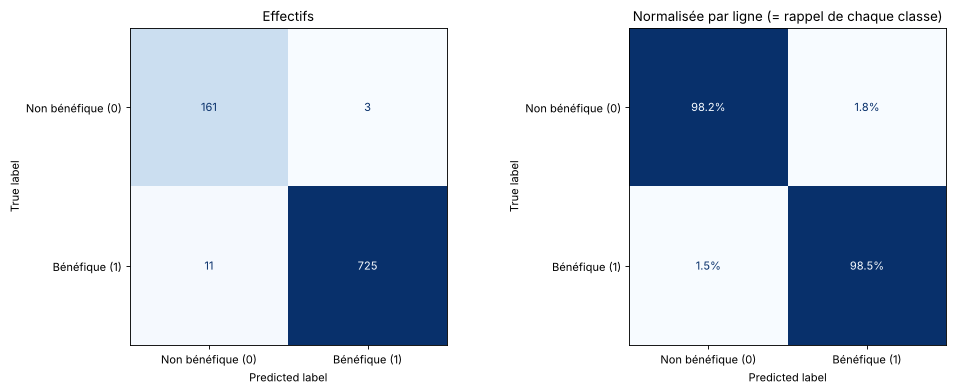

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=TARGET_NAMES,
                                        cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Effectifs')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=TARGET_NAMES, normalize='true',
                                        cmap='Blues', ax=axes[1], colorbar=False, values_format='.1%')
axes[1].set_title('Normalisée par ligne (= rappel de chaque classe)')
plt.tight_layout(); plt.show()

# Qui sont les étudiants mal classés ?
err = X_test.assign(vraie_classe=ym_test.values, prediction=y_pred)[y_pred != y_test.values]
print('Classe d\'origine (3 classes) des erreurs :', err['vraie_classe'].value_counts().to_dict())

**Interprétation.**
- 14 erreurs sur 900 : 11 étudiants *Beneficial* classés « non bénéfiques » (faux positifs côté risque) et 3 étudiants *Neutral* classés « bénéfiques ».
- **Les 33 étudiants *Negative* du test sont tous correctement détectés** ; les erreurs portent uniquement sur la frontière *Beneficial* / *Neutral*, qui est la zone de recouvrement naturelle entre les classes (voir boxplots de la section 2.3).
- La version normalisée permet de lire directement le **rappel de chaque classe**, ce que la matrice brute de l'auteur ne montrait pas.

### 6.3 Courbes ROC et précision-rappel

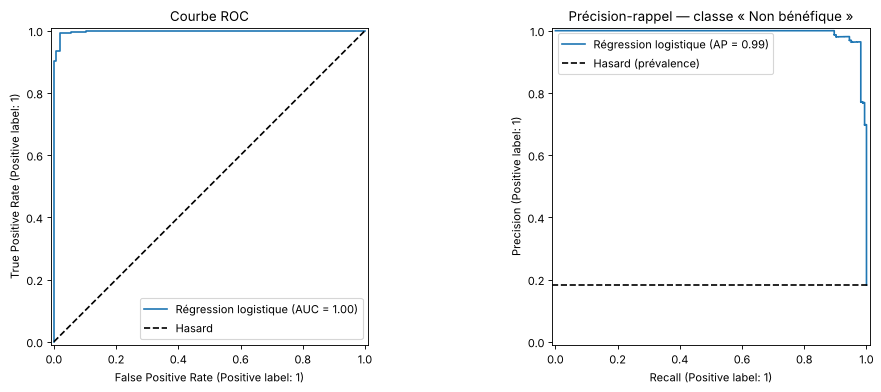

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0], name=best_name)
axes[0].plot([0, 1], [0, 1], 'k--', label='Hasard'); axes[0].legend(); axes[0].set_title('Courbe ROC')
# PR curve pour la classe minoritaire (Non bénéfique), plus exigeante
PrecisionRecallDisplay.from_predictions(1 - y_test, 1 - y_proba, ax=axes[1], name=best_name)
axes[1].axhline((1 - y_test).mean(), ls='--', color='k', label='Hasard (prévalence)')
axes[1].legend(); axes[1].set_title('Précision-rappel — classe « Non bénéfique »')
plt.tight_layout(); plt.show()

**Interprétation.**
- **ROC-AUC ≈ 0,998** : le modèle classe presque parfaitement les étudiants selon leur probabilité d'impact bénéfique.
- La courbe **précision-rappel** est plus exigeante en cas de déséquilibre (la référence « hasard » vaut 0,18 et non 0,5). Elle reste proche du coin supérieur droit : on peut obtenir à la fois un très bon rappel et une très bonne précision pour la classe minoritaire.
- Ces courbes permettent aussi de **choisir le seuil de décision** selon l'usage visé, au lieu de garder 0,5 par défaut comme dans le notebook d'origine.

### 6.4 Courbes d'apprentissage : sur- ou sous-apprentissage ? *(absent du notebook d'origine)*

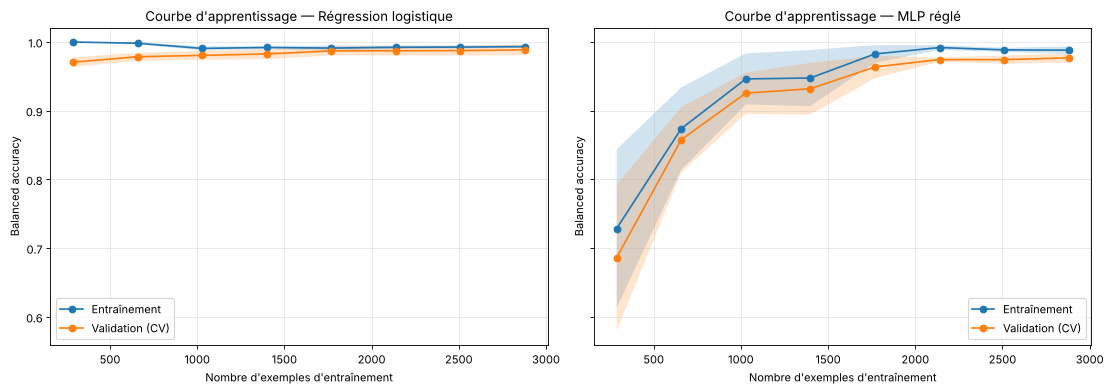

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, est) in zip(axes, [(best_name, best_model), ('MLP réglé', mlp_gs)]):
    sizes, tr, va = learning_curve(est, X_train, y_train, cv=cv, scoring='balanced_accuracy',
                                   train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
    for s, lab in [(tr, 'Entraînement'), (va, 'Validation (CV)')]:
        ax.plot(sizes, s.mean(1), 'o-', label=lab)
        ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
    ax.set_title(f'Courbe d\'apprentissage — {name}')
    ax.set_xlabel('Nombre d\'exemples d\'entraînement'); ax.set_ylabel('Balanced accuracy')
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interprétation.**
- **Régression logistique** : dès 300 exemples, le score de validation dépasse 0,97 ; les courbes d'entraînement et de validation se rejoignent vers **≈ 0,99** avec un écart très faible → **ni sur-apprentissage ni sous-apprentissage**, et ajouter des données n'apporterait presque rien.
- **MLP** : avec peu de données, il est nettement moins bon (≈ 0,69 en validation à 300 exemples) et très variable d'un pli à l'autre (zones colorées larges). Il lui faut environ 2 000 exemples pour se stabiliser, et il plafonne en dessous de la régression logistique (≈ 0,98). Un réseau de neurones a beaucoup plus de paramètres à estimer : il est **plus gourmand en données**, sans gain ici.
- C'est le diagnostic que l'auteur aurait pu faire avec l'objet `history` (courbes loss / val_loss), qu'il n'a jamais tracé.

### 6.5 Interprétation : importance des variables *(absent du notebook d'origine)*

Coefficients les plus forts (variables standardisées) :
num__Perceived_Stress_Score        -12.23
num__Mental_Health_Index             9.84
num__Academic_Performance_GPA        6.55
nom__Academic_Level_Postgraduate     1.59
nom__Device_Type_Laptop/PC          -1.34
nom__Device_Type_Smartphone          1.10
nom__Academic_Level_High School     -1.01
nom__Primary_Platform_Snapchat      -0.56


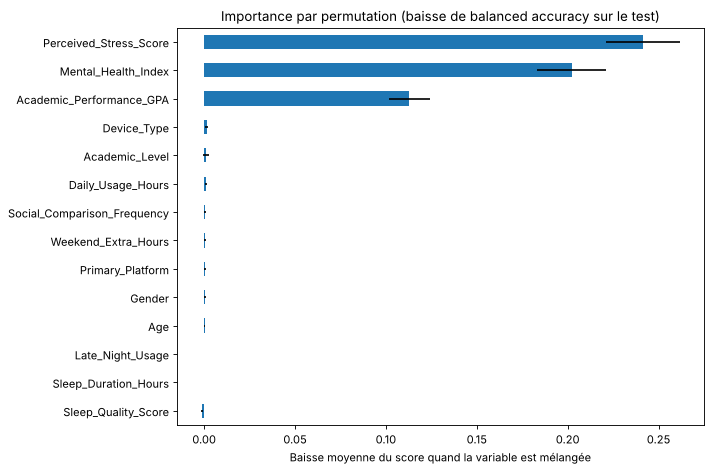

In [51]:
pi = permutation_importance(best_model, X_test, y_test, scoring='balanced_accuracy',
                            n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(9, 6))
imp.plot(kind='barh', xerr=pd.Series(pi.importances_std, index=X_test.columns)[imp.index])
plt.title('Importance par permutation (baisse de balanced accuracy sur le test)')
plt.xlabel('Baisse moyenne du score quand la variable est mélangée')
plt.tight_layout(); plt.show()

if best_name == 'Régression logistique':
    coefs = pd.Series(best_model.named_steps['model'].coef_[0],
                      index=best_model.named_steps['pre'].get_feature_names_out())
    print('Coefficients les plus forts (variables standardisées) :')
    print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8).round(2).to_string())

**Interprétation.**
- Le modèle repose presque entièrement sur **3 variables : le stress perçu, l'indice de santé mentale et le GPA**. Mélanger l'une d'elles fait chuter le score de façon nette ; les autres variables ont un effet très faible.
- `Daily_Usage_Hours`, pourtant très corrélé à la cible (−0,72), a un poids faible : à cause de la **multicolinéarité** (section 2.5), l'information qu'il porte est déjà contenue dans le stress et la santé mentale.
- Les signes des coefficients sont cohérents avec l'EDA : plus de stress → moins de chances d'impact bénéfique ; meilleure santé mentale et meilleur GPA → plus de chances.
- ⚠️ Cela pose une question de fond, traitée en 6.7.

### 6.6 Variante à 3 classes *(le modèle d'origine n'a jamais vu la classe « Negative »)*

Même pipeline, même type de modèle, mais sur la cible d'origine à 3 modalités (validation croisée sur le train, puis test).

CV 5 plis (train) : {'accuracy': '0.985 ± 0.003', 'balanced_accuracy': '0.945 ± 0.011', 'f1_macro': '0.950 ± 0.011'}

Test :
               precision    recall  f1-score   support

  Beneficial      0.993     0.993     0.993       736
     Neutral      0.939     0.947     0.943       131
    Negative      0.938     0.909     0.923        33

    accuracy                          0.983       900
   macro avg      0.957     0.950     0.953       900
weighted avg      0.983     0.983     0.983       900



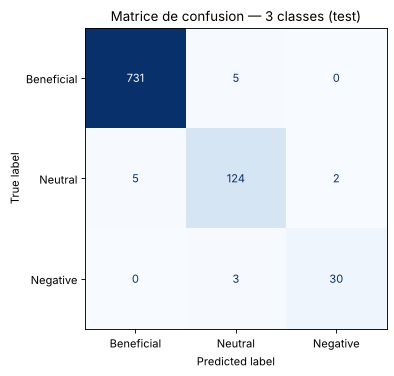

In [52]:
multi_pipe = Pipeline([('pre', make_preprocessor()),
                       ('model', LogisticRegression(max_iter=5000, random_state=SEED))])
res_m = cross_validate(multi_pipe, X_train, ym_train, cv=cv,
                       scoring=['accuracy', 'balanced_accuracy', 'f1_macro'])
print('CV 5 plis (train) :', {k[5:]: f'{v.mean():.3f} ± {v.std():.3f}' for k, v in res_m.items() if k.startswith('test_')})

multi_pipe.fit(X_train, ym_train)
ym_pred = multi_pipe.predict(X_test)
print('\nTest :\n', classification_report(ym_test, ym_pred, labels=ORDER, digits=3))
ConfusionMatrixDisplay.from_predictions(ym_test, ym_pred, labels=ORDER, cmap='Blues', colorbar=False)
plt.title('Matrice de confusion — 3 classes (test)'); plt.tight_layout(); plt.show()

**Interprétation.**
- En **3 classes**, le modèle reste très performant : F1 macro ≈ 0,95 en CV, et sur le test un rappel de **90,9 % pour *Negative*** (30 sur 33) et de 94,7 % pour *Neutral*.
- Les erreurs ne se produisent qu'entre classes **voisines** (Beneficial ↔ Neutral, Neutral ↔ Negative) : aucun étudiant *Negative* n'est classé *Beneficial*, et inversement.
- La balanced accuracy (≈ 0,945 en CV) est plus basse qu'en binaire : distinguer *Neutral* de *Negative* est plus difficile que distinguer *Beneficial* du reste.
- C'est une modélisation **plus riche** que la version binaire de l'auteur : elle distingue un impact neutre d'un impact réellement négatif, distinction perdue avec un regroupement en 0/1 (et totalement absente du notebook d'origine, qui avait supprimé la classe *Negative*).

### 6.7 Analyse critique : la cible est-elle « trop facile » à prédire ?

Dans l'EDA, les classes sont presque parfaitement séparées par le stress, l'indice de santé mentale et le GPA, et un modèle **linéaire** atteint ~99 %. Cela suggère que `Overall_Impact` a été **construite à partir de ces variables** (dataset vraisemblablement synthétique). Or ce sont des **conséquences** de l'usage des réseaux sociaux, pas des comportements d'usage.

Question plus utile en pratique : *peut-on prédire l'impact uniquement à partir des comportements (temps d'usage, plateforme, usage nocturne, comparaison sociale, appareil) et du profil ?*

In [53]:
BEHAV_NUM = ['Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Late_Night_Usage']
from sklearn.base import clone
# Même modèle et mêmes hyperparamètres que le modèle retenu, seules les variables changent
behav_pipe = Pipeline([('pre', make_preprocessor(num=BEHAV_NUM)),
                       ('model', clone(best_model.named_steps['model']))])
res_b = cross_validate(behav_pipe, X_train, y_train, cv=cv, scoring=SCORING)
full_res = cross_validate(best_model, X_train, y_train, cv=cv, scoring=SCORING)

comp = pd.DataFrame({
    'Toutes les variables': {m: full_res['test_' + m].mean() for m in SCORING},
    'Comportements + profil seulement': {m: res_b['test_' + m].mean() for m in SCORING},
}).round(3)
display(comp)

,Toutes les variables,Comportements + profil seulement
accuracy,0.987,0.876
balanced_acc,0.989,0.869
f1_macro,0.979,0.819
roc_auc,0.999,0.953


**Interprétation.**
- Sans les variables de bien-être (stress, santé mentale, GPA, sommeil), le score baisse nettement : balanced accuracy **≈ 0,87** au lieu de ≈ 0,99, ROC-AUC ≈ 0,95 au lieu de ≈ 0,999.
- Cela confirme que le score de ~98–99 % vient surtout du fait que **la cible est très proche des variables de bien-être** (elle en est probablement dérivée). Prédire `Overall_Impact` à partir du stress et de la santé mentale est donc en partie **circulaire**.
- Un modèle « comportements seulement » reste cependant **très au-dessus de la baseline** (0,87 contre 0,50) : le temps d'usage quotidien et l'usage nocturne sont de vrais signaux d'alerte.
- ➜ Le choix des variables d'entrée doit dépendre de la question posée. Pour repérer **en amont** des étudiants à risque à partir de leurs habitudes, c'est ce second modèle qui a du sens, et son score honnête est ~87 %, pas 98 %.

## 7. Conclusion

### Bilan : notebook d'origine vs pipeline corrigée

| Étape | Notebook d'origine | Pipeline corrigée (Partie 2) |
|---|---|---|
| **Data** | Pas de définition du problème | Problème, cible et types de variables définis |
| **EDA** | 13 graphiques sans interprétation, cible jamais étudiée, heatmap incomplète | Cible, cible ↔ variables, catégorielles, corrélations complètes, outliers, cohérence, manquants, tous commentés |
| **Prétraitement** | 2 bugs → **293 lignes perdues (6,5 %)**, classe *Negative* supprimée | 4 500 lignes conservées, mapping contrôlé par `assert`, split stratifié sur 3 classes |
| **Transformation** | Encodage hors pipeline, ordinal en one-hot | `Pipeline` + `ColumnTransformer` (médiane, scaler, ordinal, one-hot), sans fuite |
| **ML** | 1 réseau, 1 split, pas de seed ni de baseline | Baseline + 4 modèles en **CV stratifiée 5 plis**, `GridSearchCV`, seed fixée |
| **Évaluation** | Accuracy 98,3 % (sur données amputées) + matrice brute | Accuracy **98,4 %**, balanced accuracy **98,3 %**, ROC-AUC **0,998**, rapport par classe, ROC/PR, courbes d'apprentissage, importance des variables, 3 classes, analyse de la cible |

### À retenir
1. **Le score de l'auteur était trompeur** : obtenu sans la classe *Negative*, sans validation croisée et sans baseline (84,9 % « gratuits »).
2. **Un modèle simple suffit** : la régression logistique bat le réseau de neurones et reste interprétable.
3. **Les erreurs silencieuses sont les plus dangereuses** : `errors='coerce'` + `dropna()` ont caché deux bugs. Il faut toujours contrôler la taille des données à chaque étape.
4. **Le score très élevé s'explique surtout par la construction de la cible** : sans les variables de bien-être, la performance réaliste est d'environ 87 % de balanced accuracy.

### Pistes d'amélioration
- Ajuster le **seuil de décision** selon le coût d'un faux négatif (étudiant à risque non détecté).
- Tester un **modèle de régression** sur `Mental_Health_Index` à partir des seuls comportements, plus intéressant qu'une cible quasi déterministe.
- Regrouper les modalités rares et tester une sélection de variables (multicolinéarité).
- Si l'on veut garder Keras : intégrer le réseau dans une boucle `StratifiedKFold` avec `EarlyStopping(restore_best_weights=True)` et `tf.random.set_seed`.
